## **Phase 1 — Business Understanding, Data Audit and Preparation**

In [3]:
import pandas as pd
import numpy as np


In [4]:
df = pd.read_csv(r"C:\Users\ASUS\Downloads\ai4i+2020+predictive+maintenance+dataset\ai4i2020.csv")

In [5]:
df.shape

(10000, 14)

In [6]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [7]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [8]:
df.columns.tolist()

['UDI',
 'Product ID',
 'Type',
 'Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]',
 'Machine failure',
 'TWF',
 'HDF',
 'PWF',
 'OSF',
 'RNF']

In [9]:
df.dtypes

UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [11]:
display(df.describe(include='all'))

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
unique,NaN,10000,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,M24859,L,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,5000.50000,NaN,NaN,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,NaN,NaN,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,NaN,NaN,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,NaN,NaN,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,NaN,NaN,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,NaN,NaN,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000



#### Missing Values and Duplicate Records

In [12]:
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df)) * 100
})

display(missing)

,Missing_Count,Missing_Percentage
UDI,0,0.0
Product ID,0,0.0
Type,0,0.0
Air temperature [K],0,0.0
Process temperature [K],0,0.0
Rotational speed [rpm],0,0.0
Torque [Nm],0,0.0
Tool wear [min],0,0.0
Machine failure,0,0.0
TWF,0,0.0


In [13]:
print("Total duplicate rows:", df.duplicated().sum())

print("Duplicate UDI values:", df['UDI'].duplicated().sum())

print("Duplicate Product ID values:", df['Product ID'].duplicated().sum())

Total duplicate rows: 0
Duplicate UDI values: 0
Duplicate Product ID values: 0


In [14]:
# This checks whether categorical fields contain visually empty values that isnull() cannot detect.
string_cols = df.select_dtypes(include=['object', 'string']).columns

for col in string_cols:
    empty_count = df[col].eq('').sum()
    whitespace_count = df[col].apply(
        lambda x: isinstance(x, str) and x.strip() == '' and x != ''
    ).sum()

    print(f"\nColumn: {col}")
    print("Empty strings:", empty_count)
    print("Whitespace-only strings:", whitespace_count)


Column: Product ID
Empty strings: 0
Whitespace-only strings: 0

Column: Type
Empty strings: 0
Whitespace-only strings: 0


In [15]:
for col in string_cols:
    print(f"\n{'='*40}")
    print(f"Column: {col}")
    print(df[col].value_counts(dropna=False))


Column: Product ID
Product ID
M24859    1
M14860    1
L47181    1
L47182    1
L47183    1
         ..
M14879    1
H29434    1
L47201    1
M14882    1
L47203    1
Name: count, Length: 10000, dtype: int64

Column: Type
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


In [16]:
# Product ID prefix alignment
# This will tell us whether the identifier prefix and product category are aligned.
df['Product_ID_Prefix'] = df['Product ID'].str[:1]

print("Product ID Prefix Distribution:")
display(df['Product_ID_Prefix'].value_counts(dropna=False))

print("\nProduct ID Prefix vs Type:")
display(pd.crosstab(
    df['Product_ID_Prefix'],
    df['Type'],
    margins=True
))

mismatch = df[
    df['Product_ID_Prefix'] != df['Type']
]

print("\nPrefix and Type mismatches:", len(mismatch))

if len(mismatch) > 0:
    display(mismatch[['Product ID', 'Type', 'Product_ID_Prefix']].head(20))

Product ID Prefix Distribution:


Product_ID_Prefix
L    6000
M    2997
H    1003
Name: count, dtype: int64


Product ID Prefix vs Type:


Type,H,L,M,All
Product_ID_Prefix,,,,
H,1003,0,0,1003
L,0,6000,0,6000
M,0,0,2997,2997
All,1003,6000,2997,10000



Prefix and Type mismatches: 0


In [17]:
# Check infinite values
# We need to identify positive or negative infinity values because they can cause problems during preprocessing and model training.
numeric_cols = df.select_dtypes(include=np.number).columns

infinity_counts = pd.Series({
    col: np.isinf(df[col]).sum()
    for col in numeric_cols
})

print("Infinite values by numerical column:")
display(infinity_counts)

Infinite values by numerical column:


UDI                        0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [18]:
# Check common sentinel values
sentinel_values = [-9999, -999, -99, -1, 9999, 99999]
sentinel_results = {}

for col in numeric_cols:
    counts = {
        value: (df[col] == value).sum()
        for value in sentinel_values
    }

    sentinel_results[col] = counts

sentinel_df = pd.DataFrame(sentinel_results).T

print("Sentinel Value Audit:")
display(sentinel_df)
# These values are candidates for investigation, not automatically invalid observations.

Sentinel Value Audit:


,-9999,-999,-99,-1,9999,99999
UDI,0,0,0,0,1,0
Air temperature [K],0,0,0,0,0,0
Process temperature [K],0,0,0,0,0,0
Rotational speed [rpm],0,0,0,0,0,0
Torque [Nm],0,0,0,0,0,0
Tool wear [min],0,0,0,0,0,0
Machine failure,0,0,0,0,0,0
TWF,0,0,0,0,0,0
HDF,0,0,0,0,0,0
PWF,0,0,0,0,0,0


In [19]:
# Verify binary target and failure-mode flags
binary_cols = [
    'Machine failure',
    'TWF',
    'HDF',
    'PWF',
    'OSF',
    'RNF'
]

for col in binary_cols:
    unique_values = set(df[col].dropna().unique())

    invalid_values = unique_values - {0, 1}

    print(f"\nColumn: {col}")
    print("Unique values:", sorted(unique_values))
    print("Invalid values:", invalid_values)
    print("Missing values:", df[col].isnull().sum())
    print("Valid binary column:", len(invalid_values) == 0
          and df[col].notna().all())


Column: Machine failure
Unique values: [np.int64(0), np.int64(1)]
Invalid values: set()
Missing values: 0
Valid binary column: True

Column: TWF
Unique values: [np.int64(0), np.int64(1)]
Invalid values: set()
Missing values: 0
Valid binary column: True

Column: HDF
Unique values: [np.int64(0), np.int64(1)]
Invalid values: set()
Missing values: 0
Valid binary column: True

Column: PWF
Unique values: [np.int64(0), np.int64(1)]
Invalid values: set()
Missing values: 0
Valid binary column: True

Column: OSF
Unique values: [np.int64(0), np.int64(1)]
Invalid values: set()
Missing values: 0
Valid binary column: True

Column: RNF
Unique values: [np.int64(0), np.int64(1)]
Invalid values: set()
Missing values: 0
Valid binary column: True


In [20]:
# Target and failure-mode consistency
failure_flags = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']

df['Any_Failure_Mode'] = df[failure_flags].any(axis=1).astype(int)

print("Machine Failure vs Any Failure Mode:")

display(pd.crosstab(
    df['Machine failure'],
    df['Any_Failure_Mode'],
    margins=True
))

print("\nFailure records without any failure-mode indicator:",
      ((df['Machine failure'] == 1) &
       (df['Any_Failure_Mode'] == 0)).sum())

print("\nRecords with failure-mode indicator but no machine failure:",
      ((df['Machine failure'] == 0) &
       (df['Any_Failure_Mode'] == 1)).sum())

Machine Failure vs Any Failure Mode:


Any_Failure_Mode,0,1,All
Machine failure,,,
0,9643,18,9661
1,9,330,339
All,9652,348,10000



Failure records without any failure-mode indicator: 9

Records with failure-mode indicator but no machine failure: 18


## Outlier detection 

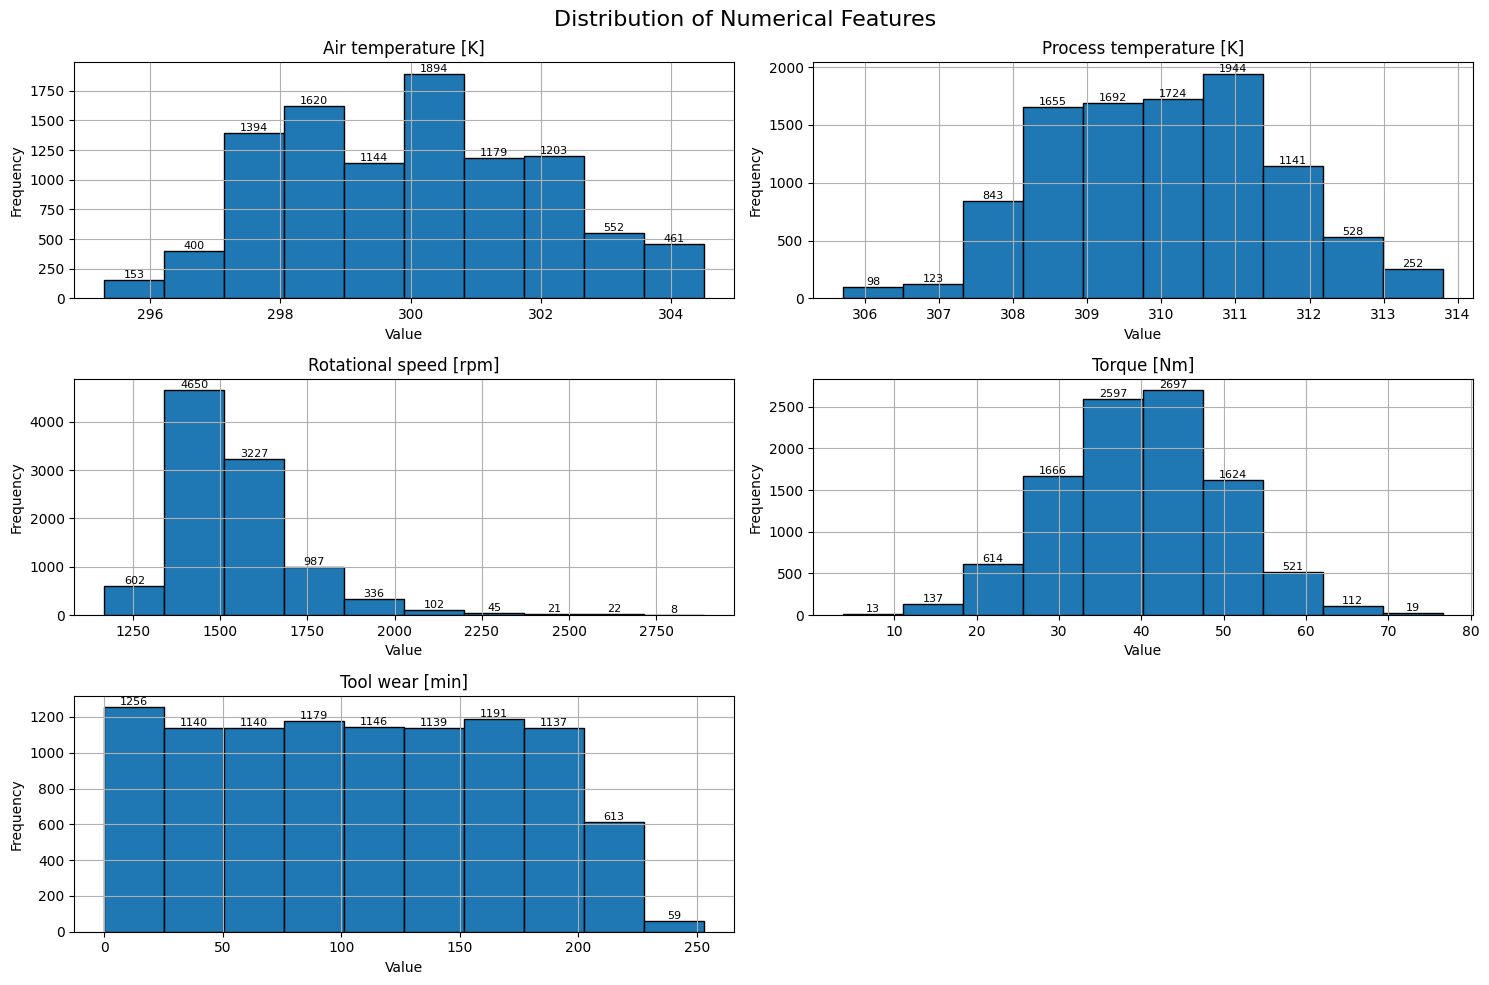

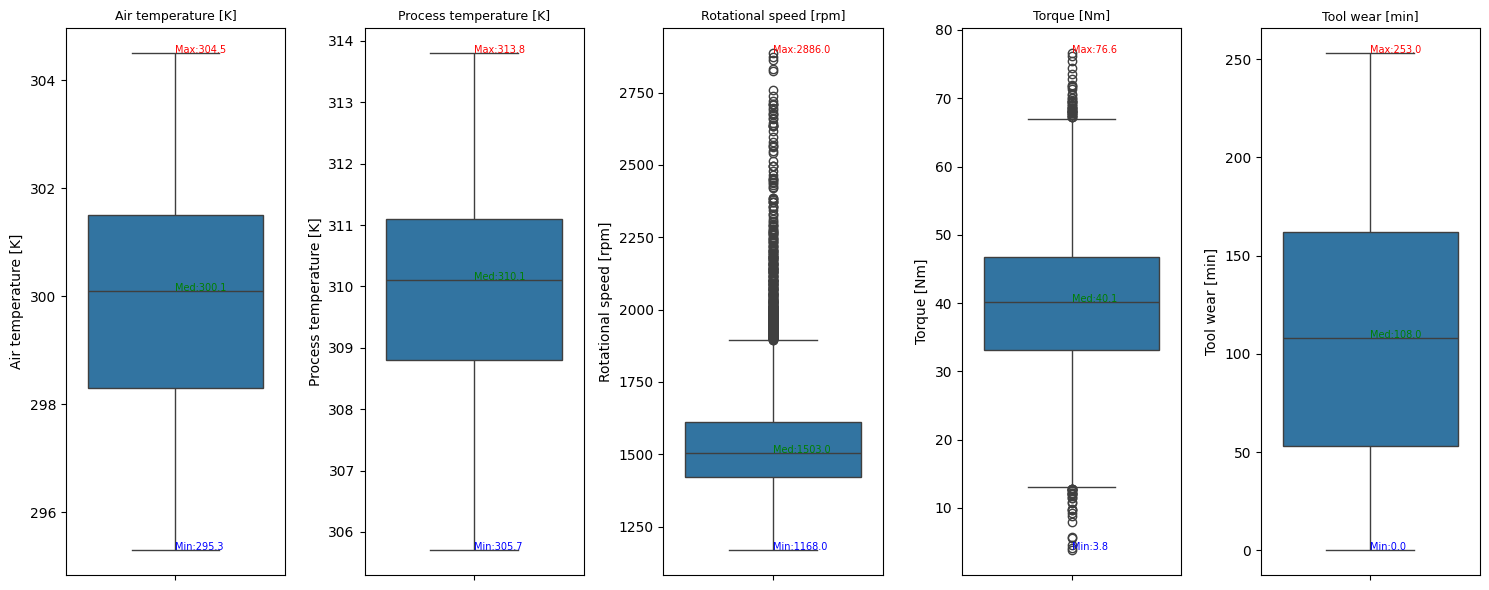

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Numerical columns
numerical_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

# ==========================
# HISTOGRAMS
# ==========================
axes = df[numerical_features].hist(
    figsize=(15, 10),
    bins=10,              # Reduced bins so values are visible
    edgecolor='black'
)

# Add labels and frequencies
for ax in axes.flatten():
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

    for patch in ax.patches:
        height = patch.get_height()

        if height > 0:
            ax.annotate(
                f'{int(height)}',
                (patch.get_x() + patch.get_width()/2, height),
                ha='center',
                va='bottom',
                fontsize=8,
                rotation=0
            )

plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()


# ==========================
# BOXPLOTS
# ==========================
plt.figure(figsize=(15, 6))

for i, col in enumerate(numerical_features, 1):
    plt.subplot(1, 5, i)

    sns.boxplot(y=df[col])

    plt.title(col, fontsize=9)
    plt.ylabel(col)
    plt.xlabel('')

    # Display Min, Max, Median values
    min_val = df[col].min()
    max_val = df[col].max()
    median_val = df[col].median()

    plt.text(
        0,
        min_val,
        f'Min:{min_val:.1f}',
        fontsize=7,
        color='blue'
    )

    plt.text(
        0,
        median_val,
        f'Med:{median_val:.1f}',
        fontsize=7,
        color='green'
    )

    plt.text(
        0,
        max_val,
        f'Max:{max_val:.1f}',
        fontsize=7,
        color='red'
    )

plt.tight_layout()
plt.show()

In [22]:
# Calculate IQR outlier counts
outlier_results = []

for col in numerical_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    lower_outliers = (df[col] < lower_bound).sum()
    upper_outliers = (df[col] > upper_bound).sum()

    outlier_results.append({
        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Lower Outliers': lower_outliers,
        'Upper Outliers': upper_outliers,
        'Total Outliers': lower_outliers + upper_outliers
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Lower Outliers,Upper Outliers,Total Outliers
0,Air temperature [K],298.3,301.5,3.2,293.50,306.30,0,0,0
1,Process temperature [K],308.8,311.1,2.3,305.35,314.55,0,0,0
2,Rotational speed [rpm],1423.0,1612.0,189.0,1139.50,1895.50,0,418,418
3,Torque [Nm],33.2,46.8,13.6,12.80,67.20,28,41,69
4,Tool wear [min],53.0,162.0,109.0,-110.50,325.50,0,0,0


In [23]:
# Investigate extreme readings
# Calculate the IQR boundaries
outlier_features = [
    'Rotational speed [rpm]',
    'Torque [Nm]'
]

for col in outlier_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    print(f"\n{col}")
    print("Lower boundary:", lower)
    print("Upper boundary:", upper)

    print("\nLowest 10 values:")
    print(df.nsmallest(10, col)[[col, 'Machine failure']])

    print("\nHighest 10 values:")
    print(df.nlargest(10, col)[[col, 'Machine failure']])


Rotational speed [rpm]
Lower boundary: 1139.5
Upper boundary: 1895.5

Lowest 10 values:
      Rotational speed [rpm]  Machine failure
994                     1168                0
8437                    1181                1
6404                    1183                0
3584                    1192                0
7763                    1200                1
1970                    1202                0
7272                    1202                0
7285                    1202                0
2616                    1207                0
429                     1208                0

Highest 10 values:
      Rotational speed [rpm]  Machine failure
1784                    2886                1
463                     2874                1
50                      2861                1
847                     2833                1
4296                    2825                1
3369                    2760                1
1391                    2737                1
1095             

In [24]:
# Compare failure rates across outlier groups
# Create a copy for analysis
analysis_df = df.copy()

# Rotational speed groups
analysis_df['Speed_Group'] = 'Within IQR'
analysis_df.loc[
    analysis_df['Rotational speed [rpm]'] > 1895.5,
    'Speed_Group'
] = 'Upper Outlier'

analysis_df.loc[
    analysis_df['Rotational speed [rpm]'] < 1139.5,
    'Speed_Group'
] = 'Lower Outlier'

# Torque groups
analysis_df['Torque_Group'] = 'Within IQR'

analysis_df.loc[
    analysis_df['Torque [Nm]'] < 12.8,
    'Torque_Group'
] = 'Lower Outlier'

analysis_df.loc[
    analysis_df['Torque [Nm]'] > 67.2,
    'Torque_Group'
] = 'Upper Outlier'


# Failure rate by rotational speed group
speed_failure = analysis_df.groupby('Speed_Group')['Machine failure'].agg(
    Total_Records='count',
    Failure_Count='sum',
    Failure_Rate='mean'
)

speed_failure['Failure_Rate'] *= 100

print("Failure Rate by Rotational Speed Group")
display(speed_failure)


# Failure rate by torque group
torque_failure = analysis_df.groupby('Torque_Group')['Machine failure'].agg(
    Total_Records='count',
    Failure_Count='sum',
    Failure_Rate='mean'
)

torque_failure['Failure_Rate'] *= 100

print("\nFailure Rate by Torque Group")
display(torque_failure)

Failure Rate by Rotational Speed Group


,Total_Records,Failure_Count,Failure_Rate
Speed_Group,,,
Upper Outlier,418,35,8.373206
Within IQR,9582,304,3.172615



Failure Rate by Torque Group


,Total_Records,Failure_Count,Failure_Rate
Torque_Group,,,
Lower Outlier,24,22,91.666667
Upper Outlier,40,36,90.000000
Within IQR,9936,281,2.828100


* torque outliers have a much higher observed machine-failure rate than records within the IQR range.

my earlier IQR calculation reported:
- Torque lower outliers: 28
- Torque upper outliers: 41
- Total: 69
- But your latest group analysis reports:
- Torque lower outliers: 24
- Torque upper outliers: 40
- Total: 64

In [25]:
# Recalculate using the exact IQR boundaries
# Calculate exact torque boundaries
Q1 = df['Torque [Nm]'].quantile(0.25)
Q3 = df['Torque [Nm]'].quantile(0.75)
IQR = Q3 - Q1

lower_torque = Q1 - 1.5 * IQR
upper_torque = Q3 + 1.5 * IQR

# Create torque groups using exact boundaries
analysis_df = df.copy()

analysis_df['Torque_Group'] = 'Within IQR'

analysis_df.loc[
    analysis_df['Torque [Nm]'] < lower_torque,
    'Torque_Group'
] = 'Lower Outlier'

analysis_df.loc[
    analysis_df['Torque [Nm]'] > upper_torque,
    'Torque_Group'
] = 'Upper Outlier'

# Recalculate failure statistics
torque_failure_check = analysis_df.groupby('Torque_Group')[
    'Machine failure'
].agg(
    Total_Records='count',
    Failure_Count='sum',
    Failure_Rate='mean'
)

torque_failure_check['Failure_Rate'] *= 100

print("Exact boundaries:")
print("Lower:", repr(lower_torque))
print("Upper:", repr(upper_torque))

display(torque_failure_check)

Exact boundaries:
Lower: np.float64(12.800000000000011)
Upper: np.float64(67.19999999999999)


,Total_Records,Failure_Count,Failure_Rate
Torque_Group,,,
Lower Outlier,28,25,89.285714
Upper Outlier,41,37,90.243902
Within IQR,9931,277,2.789246


* Notice that both lower and upper torque outlier groups have substantially higher observed failure rates than the within-IQR group.
- Lower torque outliers have approximately 32 times the failure rate.
- Upper torque outliers have approximately 32.3 times the failure rate.

In [26]:
# Combined rotational speed and torque
# Create combined operating-condition groups

analysis_df['Speed_Torque_Group'] = 'Other'

analysis_df.loc[
    (analysis_df['Rotational speed [rpm]'] > 1895.5) &
    (analysis_df['Torque [Nm]'] < 12.8),
    'Speed_Torque_Group'
] = 'High Speed + Low Torque'

analysis_df.loc[
    (analysis_df['Rotational speed [rpm]'] > 1895.5) &
    (analysis_df['Torque [Nm]'] >= 12.8),
    'Speed_Torque_Group'
] = 'High Speed + Other Torque'

analysis_df.loc[
    (analysis_df['Rotational speed [rpm]'] <= 1895.5) &
    (analysis_df['Torque [Nm]'] < 12.8),
    'Speed_Torque_Group'
] = 'Other Speed + Low Torque'


combined_analysis = analysis_df.groupby(
    'Speed_Torque_Group'
)['Machine failure'].agg(
    Total_Records='count',
    Failure_Count='sum',
    Failure_Rate='mean'
)

combined_analysis['Failure_Rate'] *= 100

display(combined_analysis)

,Total_Records,Failure_Count,Failure_Rate
Speed_Torque_Group,,,
High Speed + Low Torque,24,22,91.666667
High Speed + Other Torque,394,13,3.299492
Other,9582,304,3.172615


IQR-based outlier analysis identified 418 potential outliers in rotational speed and 69 in torque. Further investigation showed that the upper rotational-speed outlier group had an 8.37% failure rate, while the torque lower and upper outlier groups had failure rates of 89.29% and 90.24%, respectively. A combined analysis identified 24 records with both high rotational speed and low torque, of which 22 experienced machine failure (91.67%). These observations suggest a strong association between certain operating conditions and machine failure. Since the values are not confirmed data errors, all observations were retained for modelling.

#### Correlation and sensor relationships

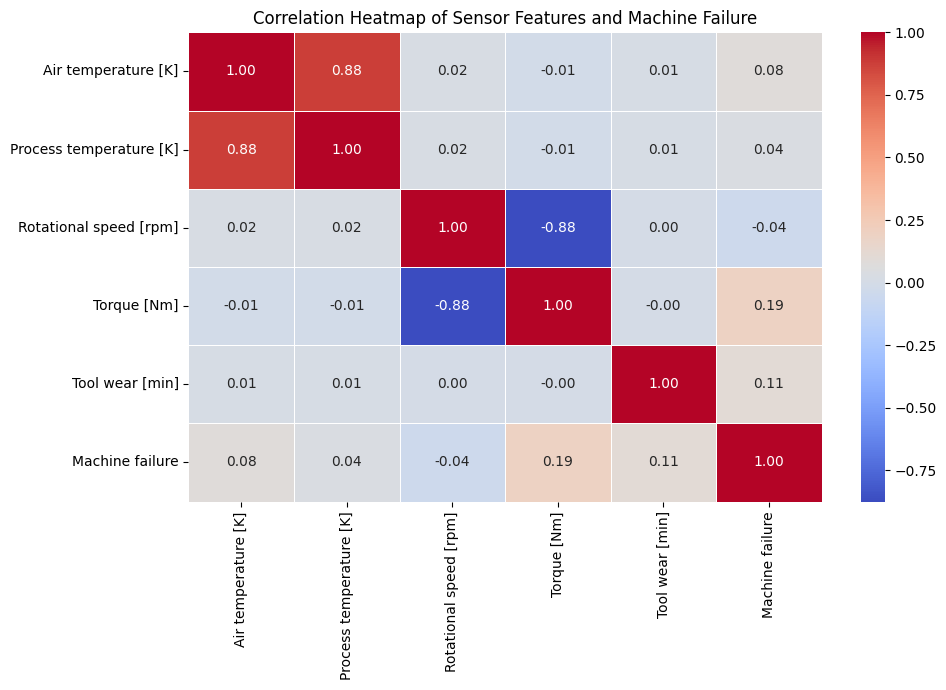

In [27]:
correlation_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]',
    'Machine failure'
]

correlation_matrix = df[correlation_features].corr(
    method='pearson'
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Sensor Features and Machine Failure')
plt.tight_layout()
plt.show()

- Torque (+0.19): Has the strongest positive Pearson correlation with machine failure among these numerical features.
- Tool wear (+0.11): Shows a weak positive linear relationship with failure.
- Air temperature (+0.08): Shows a very weak positive relationship.
- Process temperature (+0.04): Shows an even weaker positive relationship.
- Rotational speed (-0.04): Has almost no overall linear correlation with failure.
An important point: rotational speed's correlation of -0.04 does not contradict our earlier finding about high-speed and low-torque observations. Pearson correlation measures overall linear association, and it can miss patterns that occur in particular combinations or ranges of features.

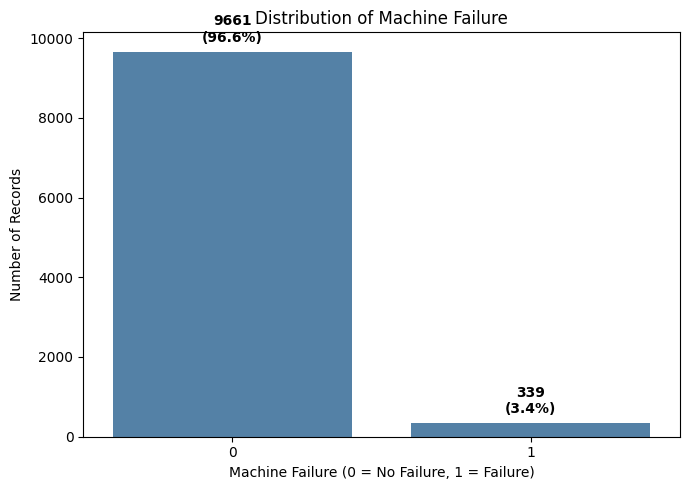

In [30]:
plt.figure(figsize=(7,5))

ax = sns.countplot(
    data=df,
    x='Machine failure',
    color='steelblue'   # use color instead of palette
)

total = len(df)

for p in ax.patches:
    count = int(p.get_height())
    percentage = count / total * 100

    ax.annotate(
        f'{count}\n({percentage:.1f}%)',
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        xytext=(0, 5),       # move label up
        textcoords='offset points'
    )

# Add extra space above bars
#ax.set_ylim(0, max(target_counts) * 1.15)

plt.title('Distribution of Machine Failure')
plt.xlabel('Machine Failure (0 = No Failure, 1 = Failure)')
plt.ylabel('Number of Records')

plt.tight_layout()
plt.show()


In [31]:
# Machine Type vs Machine Failure

type_failure = pd.crosstab(
    df['Type'],
    df['Machine failure'],
    margins=True
)

print("Machine Type vs Failure Counts")
display(type_failure)

# Calculate failure percentage by Type
type_failure_rate = df.groupby('Type')['Machine failure'].agg(
    Total_Records='count',
    Failure_Count='sum',
    Failure_Rate='mean'
)

type_failure_rate['Failure_Rate'] *= 100

print("\nFailure Rate by Machine Type")
display(type_failure_rate)

Machine Type vs Failure Counts


Machine failure,0,1,All
Type,,,
H,982,21,1003
L,5765,235,6000
M,2914,83,2997
All,9661,339,10000



Failure Rate by Machine Type


,Total_Records,Failure_Count,Failure_Rate
Type,,,
H,1003,21,2.093719
L,6000,235,3.916667
M,2997,83,2.769436


In [32]:
numerical_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

failure_comparison = df.groupby(
    'Machine failure'
)[numerical_features].agg(
    ['mean', 'median', 'min', 'max']
)

display(failure_comparison)

Air temperature [K]                       \
                               mean median    min    max   
Machine failure                                            
0                        299.973999  300.0  295.3  304.5   
1                        300.886431  301.6  295.6  304.4   

                Process temperature [K]                       \
                                   mean median    min    max   
Machine failure                                                
0                            309.995570  310.0  305.7  313.8   
1                            310.290265  310.4  306.1  313.7   

                Rotational speed [rpm]                     Torque [Nm]         \
                                  mean  median   min   max        mean median   
Machine failure                                                                 
0                          1540.260014  1507.0  1168  2695   39.629655   39.9   
1                          1496.486726  1365.0  1181  2886   50.168142   53.7   

                            Tool wear [min]                  
                  min   max            mean median min  max  
Machine failure                                              
0                12.6  70.0      106.693717  107.0   0  246  
1                 3.8  76.6      143.781711  165.0   0  253

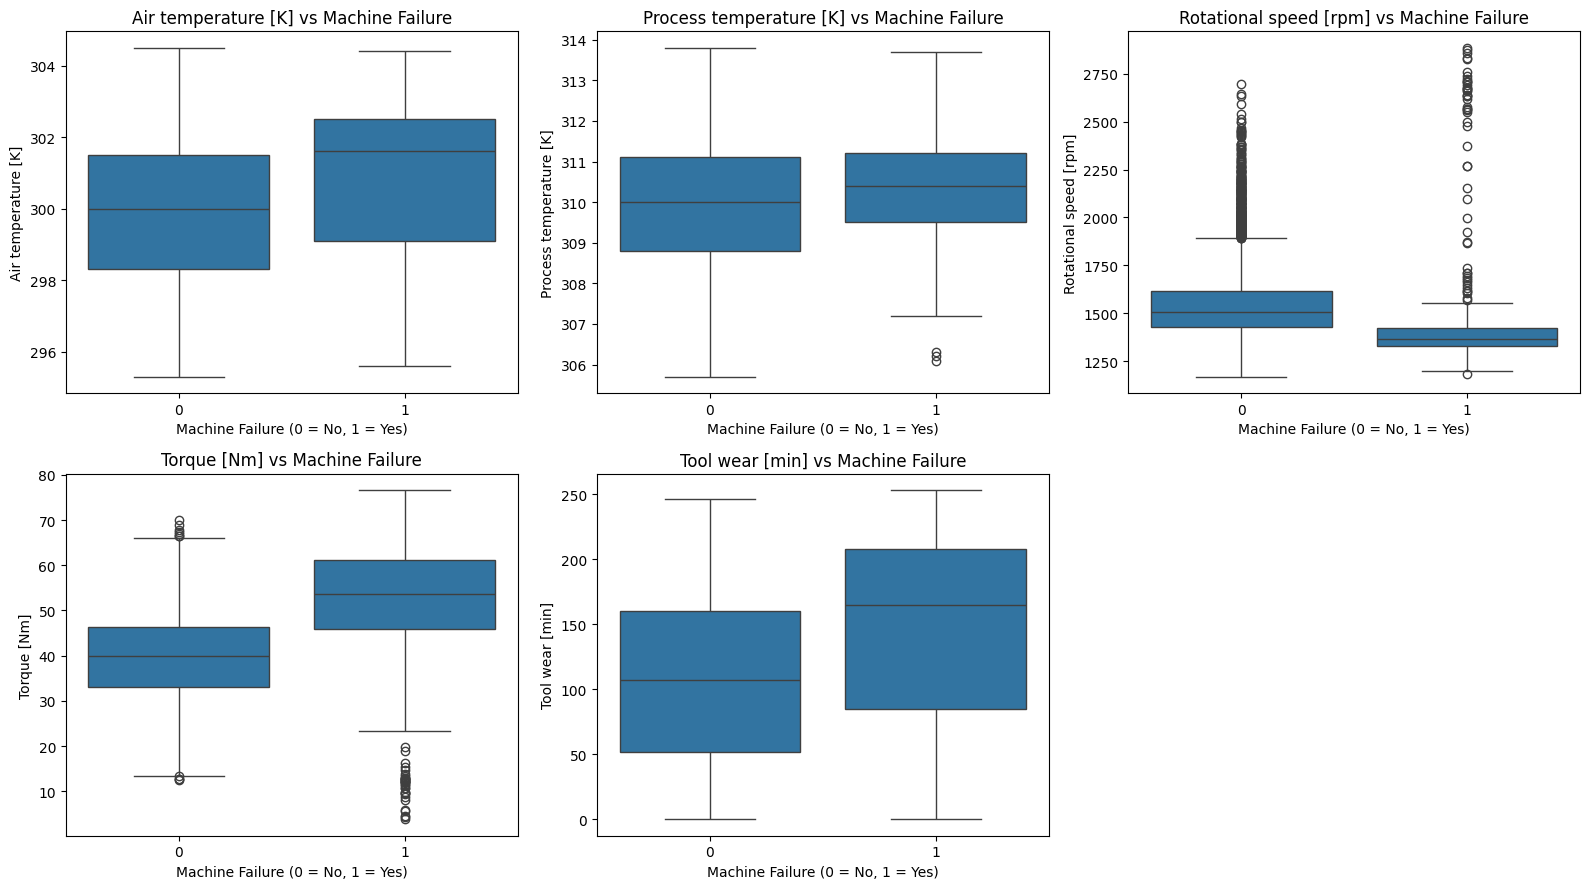

In [33]:
# Visual comparison between the two classes
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for i, col in enumerate(numerical_features):
    row = i // 3
    column = i % 3

    sns.boxplot(
        data=df,
        x='Machine failure',
        y=col,
        ax=axes[row, column]
    )

    axes[row, column].set_title(
        f'{col} vs Machine Failure'
    )

    axes[row, column].set_xlabel(
        'Machine Failure (0 = No, 1 = Yes)'
    )

axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

### Median Comparison: Machine Failure vs Non-Failure

Air temperature [K]     | Normal Med: 300.00 | Fail Med: 301.60 | Failed machines show slightly higher air temperature.

Process temperature [K] | Normal Med: 310.00 | Fail Med: 310.40 | Very little difference between the two groups.

Rotational speed [rpm]  | Normal Med: 1507.00 | Fail Med: 1365.00 | Failed machines tend to operate at lower rotational speeds.

Torque [Nm]             | Normal Med: 39.90 | Fail Med: 53.70 | Failed machines have noticeably higher torque.

Tool wear [min]         | Normal Med: 107.00 | Fail Med: 165.00 | Failed machines exhibit substantially higher tool wear.

### Key Observations

- Air temperature is slightly higher in failed machines.
- Process temperature shows minimal variation between failed and non-failed machines.
- Failed machines generally have lower rotational speeds.
- Higher torque is strongly associated with machine failures.
- Tool wear is considerably higher in failed machines, making it a potential indicator of failure risk.

* An important observation: Even when the medians differ, the distributions overlap. This means no single feature provides perfect separation between failed and non-failed machines. Combining multiple features may therefore be useful for prediction.

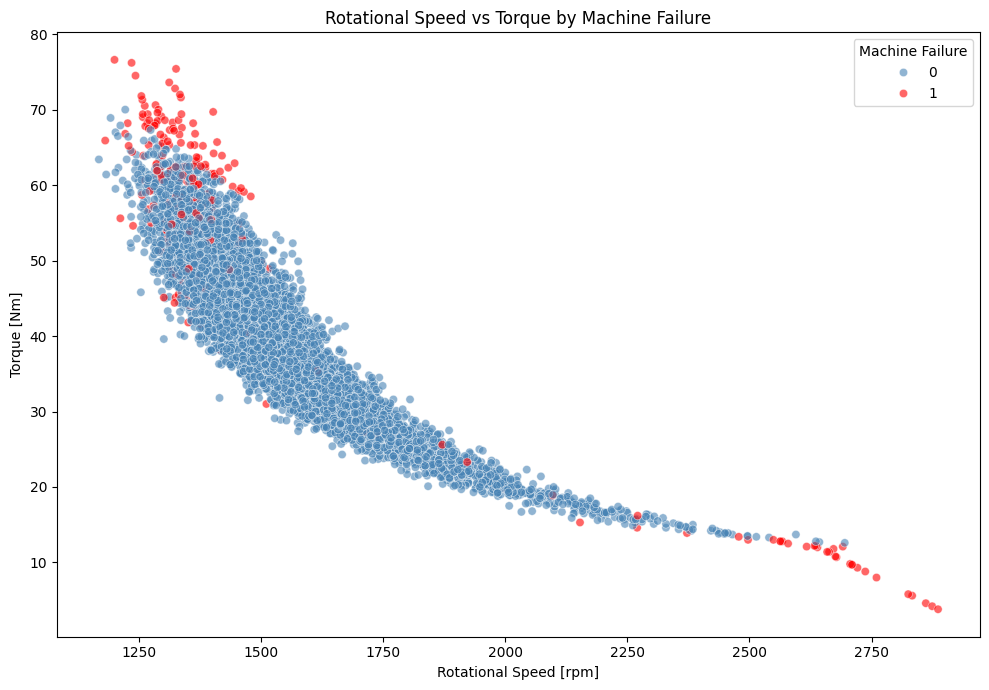

In [34]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x='Rotational speed [rpm]',
    y='Torque [Nm]',
    hue='Machine failure',
    palette={0: 'steelblue', 1: 'red'},
    alpha=0.6
)

plt.title('Rotational Speed vs Torque by Machine Failure')
plt.xlabel('Rotational Speed [rpm]')
plt.ylabel('Torque [Nm]')
plt.legend(title='Machine Failure')
plt.tight_layout()
plt.show()

# Phase 1 Conclusion

Phase 1 established the business problem, examined the dataset, investigated data quality, and explored relationships between operating measurements and machine failures.

The dataset contains **10,000 records** and **14 columns**. The audit identified no missing values, duplicate records, category mismatches, or invalid binary values in the inspected fields.

The target variable is significantly imbalanced, with **339 machine-failure records (3.39%)** and **9,661 non-failure records (96.61%)**.

The IQR-based outlier investigation identified **418 potential rotational-speed outliers** and **69 potential torque outliers**. These observations were retained because they were not confirmed data errors and may contain valuable predictive information related to machine failure.

Correlation analysis revealed:

- A strong positive relationship between **Air Temperature** and **Process Temperature** (**+0.88**).
- A strong negative relationship between **Rotational Speed** and **Torque** (**−0.88**).

Further analysis showed that **Torque** and **Tool Wear** exhibited higher average and median values within the machine-failure group.

The combined analysis of **Rotational Speed** and **Torque** identified **24 high-speed, low-torque observations**, of which **22 resulted in machine failure**. This pattern represents a potentially important failure indicator and warrants further investigation during model development.

Based on the data audit findings:

- No unnecessary data removal was performed.
- No data imputation was required.
- The six permitted predictive features were identified.
- Mandatory data-leakage prevention rules were established.

#### **Phase 1 Outcome**

Business understanding, data auditing, exploratory data analysis, and preliminary data-preparation decisions have been completed and documented.

The dataset is ready to proceed to the **Model Preparation and Feature Engineering** stage, subject to the remaining engineering-range validation checks and the implementation of reproducible preprocessing procedures.

## **Phase 2 — ML and ANN Development**

In [35]:
# Define the input features
features = [
    'Type',
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

# Define input and target
X = df[features]
y = df['Machine failure']

# Verify selected columns
print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Input shape: (10000, 6)
Target shape: (10000,)

Input features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Target distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [36]:
# Perform stratified splitting
from sklearn.model_selection import train_test_split

# First split: 70% training and 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: divide temporary data equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Check dataset sizes
print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

Training records: 7000
Validation records: 1500
Testing records: 1500


In [37]:
# Verify class distribution
for name, target in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name} Distribution:")
    print(target.value_counts())
    print(target.value_counts(normalize=True) * 100)


Training Distribution:
Machine failure
0    6763
1     237
Name: count, dtype: int64
Machine failure
0    96.614286
1     3.385714
Name: proportion, dtype: float64

Validation Distribution:
Machine failure
0    1449
1      51
Name: count, dtype: int64
Machine failure
0    96.6
1     3.4
Name: proportion, dtype: float64

Testing Distribution:
Machine failure
0    1449
1      51
Name: count, dtype: int64
Machine failure
0    96.6
1     3.4
Name: proportion, dtype: float64


* stratified split has preserved the class distribution very closely across all three datasets.

1. All **339 machine-failure records** have been successfully distributed across the training, validation, and test datasets.

2. The machine-failure rate remains approximately **3.4%** in each subset, preserving the original class distribution through stratified sampling.

3. The **training dataset** contains **237 failure records**, providing sufficient examples for model learning.

4. Both the **validation dataset** and **test dataset** contain **51 failure records** each, ensuring reliable model evaluation.

5. The stratified split successfully maintained class balance across all datasets, reducing the risk of biased performance estimates.

In [38]:
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

print("\nOverlapping indices:")
print("Train-Val:", len(set(X_train.index) & set(X_val.index)))
print("Train-Test:", len(set(X_train.index) & set(X_test.index)))
print("Val-Test:", len(set(X_val.index) & set(X_test.index)))

Training shape: (7000, 6)
Validation shape: (1500, 6)
Testing shape: (1500, 6)

Overlapping indices:
Train-Val: 0
Train-Test: 0
Val-Test: 0


#### preprocessing

In [39]:
# Define the feature groups
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Separate categorical and numerical features
categorical_features = ['Type']

numerical_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['Type']
Numerical features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


In [40]:
# Create the preprocessing transformers
# Preprocessing for Logistic Regression and ANN
scaled_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [41]:
# Preprocessing for Random Forest
rf_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

| Model | Categorical Feature | Numerical Features |
|---------|-------------------|-------------------|
| Logistic Regression | One-Hot Encoding | StandardScaler |
| Random Forest | One-Hot Encoding | Retain Original Scale |
| Artificial Neural Network (ANN) | One-Hot Encoding | StandardScaler |

* Notice that we have only defined the transformers. We have not fitted them yet.

##### Fit using training data only

In [42]:
# Fit only on training data
X_train_scaled = scaled_preprocessor.fit_transform(X_train)

In [43]:
# Transform validation and test data using the same fitted transformer
X_val_scaled = scaled_preprocessor.transform(X_val)
X_test_scaled = scaled_preprocessor.transform(X_test)

In [44]:
# Random Forest preprocessing
X_train_rf = rf_preprocessor.fit_transform(X_train)
X_val_rf = rf_preprocessor.transform(X_val)
X_test_rf = rf_preprocessor.transform(X_test)


In [45]:
print("Scaled data shapes:")
print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

Scaled data shapes:
Training: (7000, 8)
Validation: (1500, 8)
Testing: (1500, 8)


In [46]:
print("\nRandom Forest data shapes:")
print("Training:", X_train_rf.shape)
print("Validation:", X_val_rf.shape)
print("Testing:", X_test_rf.shape)


Random Forest data shapes:
Training: (7000, 8)
Validation: (1500, 8)
Testing: (1500, 8)


### Feature Count After One-Hot Encoding

The feature count increased from **6** to **8** because:

1. The five numerical features remain unchanged, contributing **5 features**.

2. The categorical feature `Type` is transformed into **3 binary columns** through One-Hot Encoding.

3. Total feature count:

   - Numerical features: **5**
   - One-Hot Encoded Type columns: **3**
   - **Total: 5 + 3 = 8 features**

---

#### Leakage Prevention Verification

The preprocessing pipeline follows the correct machine learning workflow:

1. `fit_transform()` was applied only to the **training dataset**.

2. `transform()` was applied to the **validation dataset**.

3. `transform()` was applied to the **test dataset**.

As a result, the validation and test datasets did not influence the scaling parameters or category encodings learned from the training data.

#### Conclusion

The preprocessing procedure successfully prevents **data leakage**, ensuring that model evaluation on the validation and test datasets remains unbiased and representative of real-world performance.

In [47]:
# Verify the transformed features
#Before training verify that standardization worked correctly.
import numpy as np

# Convert to dense arrays if necessary
X_train_check = (
    X_train_scaled.toarray()
    if hasattr(X_train_scaled, "toarray")
    else X_train_scaled
)

# Display transformed feature names
print("Transformed feature names:")
print(scaled_preprocessor.get_feature_names_out())

# Check numerical feature means
print("\nTraining numerical feature means:")
print(np.mean(X_train_check[:, :5], axis=0))

# Check numerical feature standard deviations
print("\nTraining numerical feature standard deviations:")
print(np.std(X_train_check[:, :5], axis=0))


Transformed feature names:
['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']

Training numerical feature means:
[ 3.13279561e-15  5.18403971e-15 -1.73480278e-16  6.71732511e-16
  9.70017717e-17]

Training numerical feature standard deviations:
[1. 1. 1. 1. 1.]


* All five numerical features have been standardized correctly.

#### Establish the baseline model: Logistic Regression

In [48]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
lr_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

# Train using training data only
lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Predict classes
y_val_pred_lr = lr_model.predict(X_val_scaled)

# Predict probabilities
y_val_prob_lr = lr_model.predict_proba(X_val_scaled)[:, 1]

# Calculate metrics
print("Logistic Regression - Validation Results")

print("Accuracy:", accuracy_score(y_val, y_val_pred_lr))
print("Precision:", precision_score(y_val, y_val_pred_lr, zero_division=0))
print("Recall:", recall_score(y_val, y_val_pred_lr, zero_division=0))
print("F1-score:", f1_score(y_val, y_val_pred_lr, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob_lr))
print("PR-AUC:", average_precision_score(y_val, y_val_prob_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_lr))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_lr, zero_division=0))

Logistic Regression - Validation Results
Accuracy: 0.8346666666666667
Precision: 0.13653136531365315
Recall: 0.7254901960784313
F1-score: 0.22981366459627328
ROC-AUC: 0.8750321384592484
PR-AUC: 0.3829018996124119

Confusion Matrix:
[[1215  234]
 [  14   37]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.84      0.91      1449
           1       0.14      0.73      0.23        51

    accuracy                           0.83      1500
   macro avg       0.56      0.78      0.57      1500
weighted avg       0.96      0.83      0.88      1500



#### Important Observation

The use of `class_weight='balanced'` helped the Logistic Regression model pay more attention to the minority machine-failure class.

However, at the default classification threshold of **0.5**, the model produced:

- **37 True Positives (correctly detected failures)**
- **234 False Positives (false alarms)**
- **14 False Negatives (missed failures)**
- **1,215 True Negatives (correctly identified non-failures)**

This indicates that the model achieved high recall for the failure class but generated a substantial number of false alarms.

#### Decision for the Baseline Model

The current Logistic Regression model will be retained as the **baseline model** using the default classification threshold of **0.5**.

Threshold tuning will not be performed at this stage because:

1. A baseline model should first be evaluated using its standard decision threshold.
2. Changing the threshold before establishing the baseline could make comparisons with later models less objective.
3. Future model improvements should be measured against a consistent baseline configuration.


#### Baseline Conclusion

The baseline Logistic Regression model demonstrates strong failure detection capability through its high recall (**72.5%**) but suffers from low precision (**13.7%**) due to a large number of false-positive predictions. This trade-off is expected in highly imbalanced classification problems and provides a useful benchmark for evaluating more advanced models in subsequent phases.

#### Train the Random Forest model

In [50]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_rf, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [51]:
y_val_pred_rf = rf_model.predict(X_val_rf)
y_val_prob_rf = rf_model.predict_proba(X_val_rf)[:, 1]

print("Random Forest - Validation Results")
print("Accuracy:", accuracy_score(y_val, y_val_pred_rf))
print("Precision:", precision_score(y_val, y_val_pred_rf, zero_division=0))
print("Recall:", recall_score(y_val, y_val_pred_rf, zero_division=0))
print("F1-score:", f1_score(y_val, y_val_pred_rf, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob_rf))
print("PR-AUC:", average_precision_score(y_val, y_val_prob_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf, zero_division=0))

Random Forest - Validation Results
Accuracy: 0.978
Precision: 0.8214285714285714
Recall: 0.45098039215686275
F1-score: 0.5822784810126582
ROC-AUC: 0.9691809090786074
PR-AUC: 0.6688170342932616

Confusion Matrix:
[[1444    5]
 [  28   23]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1449
           1       0.82      0.45      0.58        51

    accuracy                           0.98      1500
   macro avg       0.90      0.72      0.79      1500
weighted avg       0.98      0.98      0.97      1500



In [52]:
model_comparison = pd.DataFrame([
    {
        'Model': 'Logistic Regression',
        'Accuracy': 0.834667,
        'Precision': 0.136531,
        'Recall': 0.725490,
        'F1-score': 0.229814,
        'ROC-AUC': 0.875032,
        'PR-AUC': 0.382902
    },
    {
        'Model': 'Random Forest',
        'Accuracy': 0.978000,
        'Precision': 0.821429,
        'Recall': 0.450980,
        'F1-score': 0.582278,
        'ROC-AUC': 0.969181,
        'PR-AUC': 0.668817
    }
])

display(model_comparison)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.834667,0.136531,0.72549,0.229814,0.875032,0.382902
1,Random Forest,0.978000,0.821429,0.45098,0.582278,0.969181,0.668817


### Random Forest Observations

- Correctly identified **23 out of 51 failures**.
- Missed **28 actual failures**.
- Incorrectly flagged only **5 non-failure machines**.
- Failure predictions are more reliable, but many failures are still missed.

### Business Impact

There are two important types of mistakes:

- **False Negative (FN):** The model predicts a machine is safe, but it actually fails.
- **False Positive (FP):** The model predicts a failure, but the machine is actually healthy.

| Model | False Positives | False Negatives |
|---------|---------:|---------:|
| Logistic Regression | 234 | 14 |
| Random Forest | 5 | 28 |

### Key Takeaway

- **Logistic Regression** catches more failures but creates many false alarms.
- **Random Forest** creates very few false alarms but misses many failures.

The better model depends on whether the business considers a missed failure more costly than an unnecessary inspection.

### Why Accuracy Is Not Enough

Although Random Forest achieved **97.8% accuracy**, it detected only **45.1% of actual failures**.

This shows that for an imbalanced dataset, metrics such as **Precision, Recall, F1-Score, and PR-AUC** are more informative than accuracy alone.

## ANN model

In [53]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.19.1
GPUs available: []


In [54]:
##Prepare ANN training 
import numpy as np
import tensorflow as tf
import random

from sklearn.utils.class_weight import compute_class_weight

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

# Convert sparse matrices to dense arrays if necessary
X_train_ann = (
    X_train_scaled.toarray()
    if hasattr(X_train_scaled, "toarray")
    else np.asarray(X_train_scaled)
).astype("float32")

X_val_ann = (
    X_val_scaled.toarray()
    if hasattr(X_val_scaled, "toarray")
    else np.asarray(X_val_scaled)
).astype("float32")

# Prepare target labels
y_train_ann = np.asarray(y_train).astype("float32")
y_val_ann = np.asarray(y_val).astype("float32")

# Calculate class weights using training data only
classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_ann
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Training input shape:", X_train_ann.shape)
print("Validation input shape:", X_val_ann.shape)
print("Training target shape:", y_train_ann.shape)
print("Validation target shape:", y_val_ann.shape)
print("Class weights:", class_weights)

Training input shape: (7000, 8)
Validation input shape: (1500, 8)
Training target shape: (7000,)
Validation target shape: (1500,)
Class weights: {0: 0.5175218098477007, 1: 14.767932489451477}


In [55]:
#ANN architecture
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping



In [56]:
# Build ANN model
ann_model = Sequential([
    Input(shape=(8,)),

    Dense(64, activation='relu'),
    Dense(32, activation='relu'),

    Dense(1, activation='sigmoid')
])

In [57]:
# Compile the model
ann_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='roc_auc'),
        tf.keras.metrics.AUC(
            name='pr_auc',
            curve='PR'
        )
    ]
)

## ANN Model Configuration

- `Input(shape=(8,))` accepts the 8 processed features.
- `Dense(64)` and `Dense(32)` form the two hidden layers that learn patterns related to machine failures.
- `Dense(1, activation='sigmoid')` outputs the probability of machine failure.
- `binary_crossentropy` is used as the loss function for binary classification.
- `Adam(learning_rate=0.001)` is used as the optimizer.
- Precision, Recall, ROC-AUC, and PR-AUC are monitored to evaluate model performance.

### Important Note

Early stopping is applied using **validation loss** and restores the best model weights. The final ANN model will be evaluated using the same validation metrics as Logistic Regression and Random Forest to ensure a fair comparison.

In [58]:
# Display architecture
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

#### **Train the ANN**

In [59]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

In [73]:
history = ann_model.fit(
    X_train_ann,
    y_train_ann,
    validation_data=(X_val_ann, y_val_ann),
    epochs=100,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9537 - loss: 0.0981 - pr_auc: 0.8464 - precision: 0.4216 - recall: 0.9873 - roc_auc: 0.9931 - val_accuracy: 0.9480 - val_loss: 0.1461 - val_pr_auc: 0.7075 - val_precision: 0.3826 - val_recall: 0.8627 - val_roc_auc: 0.9623
Epoch 2/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9544 - loss: 0.0986 - pr_auc: 0.8484 - precision: 0.4252 - recall: 0.9831 - roc_auc: 0.9931 - val_accuracy: 0.9500 - val_loss: 0.1391 - val_pr_auc: 0.7019 - val_precision: 0.3909 - val_recall: 0.8431 - val_roc_auc: 0.9629
Epoch 3/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9530 - loss: 0.0971 - pr_auc: 0.8495 - precision: 0.4179 - recall: 0.9873 - roc_auc: 0.9933 - val_accuracy: 0.9513 - val_loss: 0.1388 - val_pr_auc: 0.7053 - val_precision: 0.3981 - val_recall: 0.8431 - val_roc_auc: 0.9627
Epoch 4/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9547 - loss: 0.0962 - pr_auc: 0.8497 - precision: 0.4267 - recall:

* The latest run stopped at epoch 40 because validation loss did not improve for 10 consecutive epochs. It restored the weights from epoch 30.


##### **Basic hyperparameter tuning without using the test set.**

In [74]:
print("Random Forest configuration:")
print(rf_model.get_params())

Random Forest configuration:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 300, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [75]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

# Create a pipeline
rf_pipeline = Pipeline([
    ('preprocessor', rf_preprocessor),
    ('classifier', RandomForestClassifier(
        class_weight='balanced',
        criterion='gini',
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    ))
])

# Hyperparameter combinations
param_grid = {
    'classifier__n_estimators': [200, 300],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_leaf': [1, 2]
}

# Stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid search using training data only
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

rf_grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(rf_grid_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(rf_grid_search.best_score_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 300}

Best Cross-Validation PR-AUC:
0.7365937489368394


- Best cross-validation **PR-AUC: 0.73659**.
- The best-performing configuration was the same as the original Random Forest model.
- None of the 12 tested parameter combinations improved the cross-validation performance.


In [76]:
# Evaluate the tuned model on validation data
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix
)


In [77]:
# Retrieve the best tuned model
best_rf_model = rf_grid_search.best_estimator_


In [78]:
# Predict on validation data
rf_tuned_pred = best_rf_model.predict(X_val)
rf_tuned_prob = best_rf_model.predict_proba(X_val)[:, 1]


In [79]:
# Calculate metrics
print("Tuned Random Forest - Validation Results")
print("Accuracy:", accuracy_score(y_val, rf_tuned_pred))
print("Precision:", precision_score(y_val, rf_tuned_pred))
print("Recall:", recall_score(y_val, rf_tuned_pred))
print("F1-score:", f1_score(y_val, rf_tuned_pred))
print("ROC-AUC:", roc_auc_score(y_val, rf_tuned_prob))
print("PR-AUC:", average_precision_score(y_val, rf_tuned_prob))


Tuned Random Forest - Validation Results
Accuracy: 0.978
Precision: 0.8214285714285714
Recall: 0.45098039215686275
F1-score: 0.5822784810126582
ROC-AUC: 0.9691809090786074
PR-AUC: 0.6688170342932616


In [80]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_val, rf_tuned_pred))


Confusion Matrix:
[[1444    5]
 [  28   23]]


* The tuned Random Forest produced **exactly the same validation results** as your original Random Forest.

- The original Random Forest configuration remained the best among all 12 tested combinations.
- Hyperparameter tuning did not improve validation performance.
- The model correctly identified **23 of the 51 actual failures**.
- The model missed **28 failures**.
- The model generated only **5 false alarms**, indicating high precision but lower recall.


**Important:** The test set remains untouched. We have used training data for cross-validation and validation data for model comparison and selection.

### Random Forest Hyperparameter Tuning Summary

Random Forest hyperparameter tuning was performed using **GridSearchCV** with **stratified 5-fold cross-validation**. Average Precision (PR-AUC) was selected as the evaluation metric because of the imbalanced nature of the machine-failure dataset.

A total of **12 parameter combinations** were tested by varying:

- Number of estimators
- Maximum tree depth
- Minimum samples per leaf

The best configuration achieved a cross-validation Average Precision of **0.7366** and matched the original Random Forest settings:

- Estimators = 300
- Max Depth = None
- Min Samples Leaf = 1

Validation performance remained unchanged after tuning, with an Average Precision of **0.6688**. The model correctly identified **23 of 51 failures**, missed **28 failures**, and generated only **5 false positives**.

### Conclusion

The original Random Forest configuration was already the best-performing model among the tested parameter combinations. Since hyperparameter tuning did not improve validation performance, the original Random Forest model was retained for further comparison.

## **Phase 3 — Model Evaluation and Reliability Audit**

In [81]:
# need to evaluate the restored epoch-30 model, not the metrics from epoch 40.
# Generate validation probabilities using restored best weights
y_val_prob_ann = ann_model.predict(X_val_ann).ravel()

# Apply default threshold
y_val_pred_ann = (y_val_prob_ann >= 0.5).astype(int)

print("ANN - Validation Results")

print("Accuracy:",
      accuracy_score(y_val, y_val_pred_ann))

print("Precision:",
      precision_score(y_val, y_val_pred_ann, zero_division=0))

print("Recall:",
      recall_score(y_val, y_val_pred_ann, zero_division=0))

print("F1-score:",
      f1_score(y_val, y_val_pred_ann, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_val, y_val_prob_ann))

print("PR-AUC:",
      average_precision_score(y_val, y_val_prob_ann))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_ann))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_ann,
    zero_division=0
))

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 905us/step
ANN - Validation Results
Accuracy: 0.9573333333333334
Precision: 0.4329896907216495
Recall: 0.8235294117647058
F1-score: 0.5675675675675675
ROC-AUC: 0.9683351601510168
PR-AUC: 0.7383673433974769

Confusion Matrix:
[[1394   55]
 [   9   42]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.96      0.98      1449
           1       0.43      0.82      0.57        51

    accuracy                           0.96      1500
   macro avg       0.71      0.89      0.77      1500
weighted avg       0.97      0.96      0.96      1500



###  **Model Performance Comparison**

Three classification models — Logistic Regression, Random Forest, and Artificial Neural Network (ANN) — were evaluated using the validation dataset.

Since the dataset contains an imbalanced target, with only 3.39% machine failures, accuracy alone is not sufficient to evaluate model performance. Therefore, Precision, Recall, F1-score, ROC-AUC, and PR-AUC (Average Precision) were considered.

| Metric | Logistic Regression | Random Forest | ANN |
|---|---:|---:|---:|
| Accuracy | 0.8347 | 0.9780 | 0.9573 |
| Precision | 0.1365 | 0.8214 | 0.4330 |
| Recall | 0.7255 | 0.4510 | 0.8235 |
| F1-score | 0.2298 | 0.5823 | 0.5676 |
| ROC-AUC | 0.8750 | 0.9692 | 0.9683 |
| PR-AUC | 0.3829 | 0.6688 | 0.7384 |

**Observations:**

- Logistic Regression achieved a recall of 72.55%, but its precision was only 13.65%, indicating a high number of false alarms.
- Random Forest achieved the highest accuracy (97.80%) and precision (82.14%), but its recall was only 45.10%, meaning it missed more than half of the actual failures.
- ANN achieved the highest recall (82.35%) and PR-AUC (0.7384), making it the strongest model among the three for identifying potential machine failures at the default threshold of 0.5.
- Random Forest and ANN achieved similar ROC-AUC values, but ANN performed better in terms of PR-AUC.

**Conclusion:**

The results demonstrate that model selection depends on the operational objective. Random Forest is more conservative in raising failure alerts, whereas ANN identifies a larger proportion of actual failures. ANN provides the strongest overall ranking performance for the minority failure class based on PR-AUC.

### Confusion Matrix Analysis

The confusion matrices were examined to understand the types of prediction errors made by each model.

- **Logistic Regression:** Correctly identified 37 failures but generated 234 false alarms. It missed 14 actual failures.
- **Random Forest:** Generated only 5 false alarms, but missed 28 actual failures. This indicates that the model is conservative when predicting machine failures.
- **ANN:** Correctly identified 42 failures and missed only 9. It generated 55 false alarms, which is higher than Random Forest but considerably lower than Logistic Regression.

**Interpretation:**

In predictive maintenance, false negatives are particularly important because they represent machines that actually fail but are predicted as normal. ANN produced the fewest false negatives among the three models at the default threshold of 0.5. However, its false-positive count indicates that additional inspections may be required.

Therefore, the confusion matrix results support evaluating the models using operational costs rather than relying solely on accuracy.

###  Reliability Evaluation Using Classification Metrics

The evaluation metrics provide different perspectives on model reliability:

1. **Precision:** Measures how many predicted failures were actual failures. Random Forest achieved the highest precision of 82.14%.
2. **Recall:** Measures how many actual failures were successfully identified. ANN achieved the highest recall of 82.35%.
3. **F1-score:** Balances precision and recall. Logistic Regression performed poorly, while Random Forest and ANN achieved similar F1-scores.
4. **ROC-AUC:** Measures the ability to distinguish between failure and non-failure cases across different thresholds. Random Forest and ANN achieved similar scores.
5. **PR-AUC:** Evaluates the precision-recall trade-off and is particularly useful for imbalanced classification. ANN achieved the highest Average Precision of 0.7384.

**Overall observation:**

No single model performs best across every metric. ANN is better at detecting actual failures, while Random Forest is better at reducing false alarms. The final model selection should consider the relative operational impact of missed failures and unnecessary inspections.

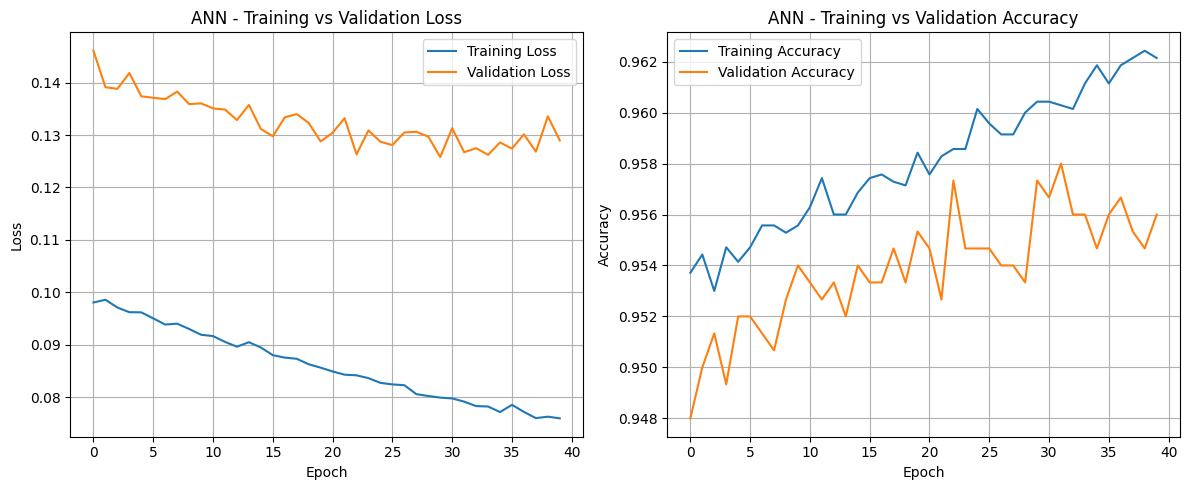

In [82]:
import matplotlib.pyplot as plt

# Plot training and validation loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('ANN - Training vs Validation Loss')
plt.legend()
plt.grid(True)

# Plot training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('ANN - Training vs Validation Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Training vs Validation Loss

- Training loss steadily decreased throughout training**from approximately 0.098 to 0.076.**
- Validation loss also decreased from **0.146 to around 0.129** but showed small fluctuations in later epochs.
- The lowest validation loss was achieved at **Epoch 30**.

**Interpretation:** The model continued learning from the training data, while improvements on validation data became smaller near the end, indicating mild overfitting.

### Training vs Validation Accuracy

- Training accuracy gradually increased to about **95.4% to 96.2%.**.
- Validation accuracy remained relatively stable between **94.8% and 95.8%**.
- The gap between training and validation accuracy remained small.

**Interpretation:** The model generalizes reasonably well to unseen data.

- The learning curves indicate good overall learning with only mild **overfitting**. Early stopping successfully selected the best model at **Epoch 30**.

**Conclusion:**

The learning curves indicate that the ANN learned useful patterns from the training data, while early stopping helped prevent unnecessary training after validation performance stopped improving consistently.

#### **threshold analysis**

* The default classification threshold is 0.5

In [83]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_results = []

for threshold in np.arange(0.1, 1.0, 0.1):

    y_pred_threshold = (
        y_val_prob_ann >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred_threshold
    ).ravel()

    threshold_results.append({
        'Threshold': round(threshold, 2),
        'Precision': precision_score(
            y_val, y_pred_threshold, zero_division=0
        ),
        'Recall': recall_score(
            y_val, y_pred_threshold, zero_division=0
        ),
        'F1-score': f1_score(
            y_val, y_pred_threshold, zero_division=0
        ),
        'False Positives': fp,
        'False Negatives': fn,
        'True Positives': tp,
        'True Negatives': tn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,True Negatives
0,0.1,0.2446,0.8824,0.3830,139,6,45,1310
1,0.2,0.3147,0.8824,0.4639,98,6,45,1351
2,0.3,0.3525,0.8431,0.4971,79,8,43,1370
3,0.4,0.3945,0.8431,0.5375,66,8,43,1383
4,0.5,0.4330,0.8235,0.5676,55,9,42,1394
5,0.6,0.4773,0.8235,0.6043,46,9,42,1403
6,0.7,0.5250,0.8235,0.6412,38,9,42,1411
7,0.8,0.5672,0.7451,0.6441,29,13,38,1420
8,0.9,0.6066,0.7255,0.6607,24,14,37,1425


* At a threshold of 0.1, the model achieved the highest recall of 88.24%, but generated 139 false positives.

 * At a threshold of 0.5, the model achieved 82.35% recall, with 55 false positives and 9 false negatives.

* At a threshold of 0.7, precision increased to 52.50%, while recall remained at 82.35%. False positives decreased to 38.

* At thresholds of 0.8 and 0.9, precision continued to improve, but recall declined to 74.51% and 72.55%, respectively.

* Notice that threshold 0.9 has the highest F1-score, but it misses five more failures than threshold 0.7

* For a predictive maintenance system, I would provisionally favour 0.7 if the business wants to maintain at least 80% recall. It reduces false alarms from 55 to 38 compared with the default 0.5 threshold, without increasing missed failures.

* This is a provisional recommendation, not a final business decision.


#### Findings
- Random Forest provides the highest precision.
- ANN provides the highest recall and PR-AUC at threshold 0.5.
- ANN achieves its highest F1-score at threshold 0.9 among the tested thresholds.
- Threshold 0.7 provides a useful provisional balance when prioritising recall of at least 80%.


#### **Hypothetical inspection & Missed-failure costs**

objective:- clearly label them as assumptions, and use those assumptions to justify our threshold recommendation.

In [84]:
inspection_cost = 2000
missed_failure_cost = 25000

model_errors = {
    "Logistic Regression": {"FP": 234, "FN": 14},
    "Random Forest": {"FP": 5, "FN": 28},
    "ANN": {"FP": 55, "FN": 9}
}

print("Business Cost Comparison - Threshold 0.5\n")

for model, errors in model_errors.items():

    fp_cost = errors["FP"] * inspection_cost
    fn_cost = errors["FN"] * missed_failure_cost
    total_cost = fp_cost + fn_cost

    print(model)
    print("False Positive Cost: ₹", fp_cost)
    print("Missed Failure Cost: ₹", fn_cost)
    print("Total Estimated Cost: ₹", total_cost)
    print("-" * 40)

Business Cost Comparison - Threshold 0.5

Logistic Regression
False Positive Cost: ₹ 468000
Missed Failure Cost: ₹ 350000
Total Estimated Cost: ₹ 818000
----------------------------------------
Random Forest
False Positive Cost: ₹ 10000
Missed Failure Cost: ₹ 700000
Total Estimated Cost: ₹ 710000
----------------------------------------
ANN
False Positive Cost: ₹ 110000
Missed Failure Cost: ₹ 225000
Total Estimated Cost: ₹ 335000
----------------------------------------


In [85]:
threshold_results = [
    {"threshold": 0.1, "FP": 139, "FN": 6},
    {"threshold": 0.2, "FP": 98, "FN": 6},
    {"threshold": 0.3, "FP": 79, "FN": 8},
    {"threshold": 0.4, "FP": 66, "FN": 8},
    {"threshold": 0.5, "FP": 55, "FN": 9},
    {"threshold": 0.6, "FP": 46, "FN": 9},
    {"threshold": 0.7, "FP": 38, "FN": 9},
    {"threshold": 0.8, "FP": 29, "FN": 13},
    {"threshold": 0.9, "FP": 24, "FN": 14}
]

for result in threshold_results:
    result["FP_Cost"] = result["FP"] * inspection_cost
    result["FN_Cost"] = result["FN"] * missed_failure_cost
    result["Total_Cost"] = (
        result["FP_Cost"] + result["FN_Cost"]
    )

import pandas as pd

cost_df = pd.DataFrame(threshold_results)

print(cost_df.to_string(index=False))

 threshold  FP  FN  FP_Cost  FN_Cost  Total_Cost
       0.1 139   6   278000   150000      428000
       0.2  98   6   196000   150000      346000
       0.3  79   8   158000   200000      358000
       0.4  66   8   132000   200000      332000
       0.5  55   9   110000   225000      335000
       0.6  46   9    92000   225000      317000
       0.7  38   9    76000   225000      301000
       0.8  29  13    58000   325000      383000
       0.9  24  14    48000   350000      398000


#### Business Cost Analysis

Model evaluation should not rely only on metrics such as Accuracy, Precision, Recall, or F1-Score. In predictive maintenance, the business impact of prediction errors is equally important.

- **False Positive (FP):** A healthy machine is predicted as a failure, leading to an unnecessary inspection.
- **False Negative (FN):** A failing machine is predicted as healthy, potentially causing downtime and repair costs.

#### Cost Assumptions

For this analysis, the following hypothetical costs were used:

| Error Type | Cost |
|------------|------|
| False Positive | ₹2,000 |
| False Negative | ₹25,000 |

The total estimated cost is calculated as:

**Total Cost = (FP × ₹2,000) + (FN × ₹25,000)**

#### Model Cost Comparison (Threshold = 0.5)

| Model | FP | FN | Total Cost |
|---------|---:|---:|-----------:|
| Logistic Regression | 234 | 14 | ₹8,18,000 |
| Random Forest | 5 | 28 | ₹7,10,000 |
| ANN | 55 | 9 | ₹3,35,000 |

#### Key Findings

- Logistic Regression detects more failures but generates many false alarms, leading to high inspection costs.
- Random Forest produces very few false alarms but misses many failures, increasing missed-failure costs.
- ANN provides the lowest overall cost at the default threshold of 0.5.

#### ANN Threshold Analysis

Different ANN thresholds were tested to find the best balance between false positives and false negatives.

The lowest estimated cost was achieved at **threshold 0.7**:

- False Positives: **38**
- False Negatives: **9**
- Total Cost: **₹3,01,000**

#### Recommendation

Based on the assumed costs, **ANN with a threshold of 0.7** is the preferred option.

It:

- Detects **42 of 51 failures** (82.35% recall).
- Reduces false alarms from **55 to 38**.
- Maintains the same number of missed failures as threshold 0.5.
- Produces the lowest estimated business cost among all tested thresholds.

#### Conclusion

Under the hypothetical cost assumptions used in this analysis, the **ANN model with a threshold of 0.7** provides the best balance between failure detection and maintenance cost. Actual deployment should use real maintenance cost data and periodic threshold review.

### **Operational Limitations & Recommendation**

The results are encouraging, but several limitations should be considered before deployment:

- The dataset is highly imbalanced, with only **3.39% failure records**, making failure detection challenging.
- The models were trained on historical data and do not use real-time sensor inputs.
- The evaluation was performed on dataset splits rather than independent industrial data.
- Prediction errors still occur. False positives may cause unnecessary inspections, while false negatives may lead to missed failures and downtime.
- The business-cost analysis used hypothetical costs, so actual results may differ in a real manufacturing environment.

#### Model Comparison

| Metric | Logistic Regression | Random Forest | ANN |
|----------|----------:|----------:|----------:|
| Accuracy | 83.47% | 97.80% | 95.73% |
| Precision | 13.65% | 82.14% | 43.30% |
| Recall | 72.55% | 45.10% | 82.35% |
| F1-Score | 0.2298 | 0.5823 | 0.5676 |
| ROC-AUC | 0.8750 | 0.9692 | 0.9683 |
| PR-AUC | 0.3829 | 0.6688 | 0.7384 |
| False Positives | 234 | 5 | 55 |
| False Negatives | 14 | 28 | 9 |
| Estimated Cost | ₹8,18,000 | ₹7,10,000 | ₹3,35,000 |

#### Key Findings

- Logistic Regression detected many failures but generated too many false alarms.
- Random Forest achieved the highest accuracy and precision but missed more failures.
- ANN achieved the highest recall and PR-AUC while producing the lowest estimated business cost.

#### Final Recommendation

The **Artificial Neural Network (ANN)** is recommended as the preferred model because it:

- Achieved the highest recall (**82.35%**).
- Achieved the highest PR-AUC (**0.7384**).
- Produced the fewest missed failures (**9 false negatives**).
- Achieved the lowest estimated business cost.

#### Recommended Configuration

| Parameter | Value |
|------------|--------|
| Model | ANN |
| Hidden Layers | 64, 32 |
| Hidden Activation | ReLU |
| Output Activation | Sigmoid |
| Optimizer | Adam |
| Learning Rate | 0.001 |
| Loss Function | Binary Cross-Entropy |
| Classification Threshold | 0.7 |
| Early Stopping | Patience = 10 |
| Best Epoch | 30 |

#### Final Conclusion

Based on both predictive performance and business-cost analysis, **ANN with a classification threshold of 0.7** provides the best balance between failure detection and inspection cost. Under the stated assumptions, it is the recommended model for this predictive maintenance assessment. Further validation using real operational data is recommended before deployment.

## **Phase 4 — Research and Controlled Experimentation**

#### Research Hypothesis

This phase evaluates whether reducing the ANN learning rate from **0.001** to **0.0005** affects machine-failure prediction performance.

The previously selected ANN achieved a **PR-AUC of 0.7384**, compared with **0.6688** for the Random Forest model. To assess the impact of learning rate, a controlled experiment will be performed while keeping the ANN architecture, preprocessing steps, training procedure, and evaluation approach unchanged.

**Null Hypothesis (H₀):** Reducing the learning rate from 0.001 to 0.0005 does not improve average validation PR-AUC.

**Alternative Hypothesis (H₁):** Reducing the learning rate from 0.001 to 0.0005 improves average validation PR-AUC.

#### Evaluation Metric

**PR-AUC (Average Precision)** is the primary evaluation metric because machine failures represent the minority class in the dataset.

The following additional metrics will also be recorded:

- Precision
- Recall
- F1-Score
- ROC-AUC
- Training Duration
- Best Epoch

#### Experimental Design

Two ANN configurations will be compared:

| Configuration | Learning Rate |
|--------------|---------------|
| Baseline ANN | 0.001 |
| Experimental ANN | 0.0005 |

All other model settings will remain unchanged.

Multiple training runs using controlled random seeds will be conducted to determine whether any performance difference is consistent across runs rather than the result of training variability.

In [86]:

# Verify the existing ANN experiment prerequisites

print("Training data shape:", X_train_scaled.shape)
print("Validation data shape:", X_val_scaled.shape)

print("\nTarget distribution in training data:")
print(y_train.value_counts().sort_index())

print("\nTarget distribution in validation data:")
print(y_val.value_counts().sort_index())

print("\nClass weights:")
print(class_weights)

print("\nTensorFlow version:", tf.__version__)

print("\nExisting ANN architecture:")
ann_model.summary()


Training data shape: (7000, 8)
Validation data shape: (1500, 8)

Target distribution in training data:
Machine failure
0    6763
1     237
Name: count, dtype: int64

Target distribution in validation data:
Machine failure
0    1449
1      51
Name: count, dtype: int64

Class weights:
{0: 0.5175218098477007, 1: 14.767932489451477}

TensorFlow version: 2.19.1

Existing ANN architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,069 (31.52 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,380 (21.02 KB)

#### **Controlled Experiment**

In [87]:
# Controlled ANN experiment configuration

import random
import time
import numpy as np
import tensorflow as tf


In [88]:
# Learning rates: only this factor will change
LEARNING_RATES = {
    "ANN_LR_0.001": 0.001,
    "ANN_LR_0.0005": 0.0005
}

In [89]:
# Paired random seeds
RANDOM_SEEDS = [42, 52, 62, 72, 82]

In [90]:
# Fixed training conditions
BATCH_SIZE = 64
MAX_EPOCHS = 100
PATIENCE = 10


In [91]:
# Existing dataset dimensions
INPUT_FEATURES = X_train_scaled.shape[1]


In [92]:
# Confirm experiment configuration
print("Learning rate configurations:", LEARNING_RATES)
print("Random seeds:", RANDOM_SEEDS)
print("Number of runs per configuration:", len(RANDOM_SEEDS))
print("Total planned training runs:",
      len(LEARNING_RATES) * len(RANDOM_SEEDS))

Learning rate configurations: {'ANN_LR_0.001': 0.001, 'ANN_LR_0.0005': 0.0005}
Random seeds: [42, 52, 62, 72, 82]
Number of runs per configuration: 5
Total planned training runs: 10


In [93]:
print("\nFixed training settings:")
print("Input features:", INPUT_FEATURES)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Class weights:", class_weights)


Fixed training settings:
Input features: 8
Batch size: 64
Maximum epochs: 100
Early stopping patience: 10
Class weights: {0: 0.5175218098477007, 1: 14.767932489451477}


**Create a reusable ANN training function**

In [94]:

def build_and_train_ann(learning_rate, seed):

    # Set random seeds for reproducibility
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

    # Attempt to enable deterministic TensorFlow operations
    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

    # Build a fresh ANN model
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(INPUT_FEATURES,)),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    # Compile model with the experiment's learning rate
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='binary_crossentropy',
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name='accuracy'),
            tf.keras.metrics.Precision(name='precision'),
            tf.keras.metrics.Recall(name='recall'),
            tf.keras.metrics.AUC(name='roc_auc'),
            tf.keras.metrics.AUC(
                name='pr_auc',
                curve='PR'
            )
        ]
    )

    # Early stopping
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=PATIENCE,
        restore_best_weights=True,
        verbose=0
    )

    # Train the model
    start_time = time.time()

    history = model.fit(
        X_train_scaled,
        y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weights,
        callbacks=[early_stopping],
        verbose=0
    )

    training_time = time.time() - start_time

    # Determine best epoch using minimum validation loss
    best_epoch = int(
        np.argmin(history.history['val_loss']) + 1
    )

    return model, history, best_epoch, training_time


In [96]:

# Test run: Baseline ANN, learning rate 0.001, seed 42

test_model, test_history, test_best_epoch, test_training_time = (
    build_and_train_ann(
        learning_rate=0.001,
        seed=42
    )
)

print("Test run completed successfully.")

print("\nLearning rate:", 0.001)
print("Random seed:", 42)
print("Best epoch:", test_best_epoch)
print("Training time:", round(test_training_time, 2), "seconds")

print("\nBest validation loss:",
      round(min(test_history.history['val_loss']), 4))

print("\nModel parameters:", test_model.count_params())


Test run completed successfully.

Learning rate: 0.001
Random seed: 42
Best epoch: 100
Training time: 25.6 seconds

Best validation loss: 0.1393

Model parameters: 2689


* One clarification: test runs are excluded from the five paired experiment runs.will start the official experiment with fresh models and the five planned seeds.

### **complete controlled experiment**

In [97]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

In [98]:
experiment_results = []

In [99]:
for experiment_name, learning_rate in LEARNING_RATES.items():

    print(f"\nStarting {experiment_name}")
    print("Learning rate:", learning_rate)

    for seed in RANDOM_SEEDS:

        print(f"Running seed {seed}...", end=" ")

        model, history, best_epoch, training_time = (
            build_and_train_ann(
                learning_rate=learning_rate,
                seed=seed
            )
        )

        # Generate validation probabilities
        y_val_prob = model.predict(
            X_val_scaled,
            verbose=0
        ).ravel()

        # Apply the same threshold of 0.5
        y_val_pred = (y_val_prob >= 0.5).astype(int)

        # Calculate validation metrics
        accuracy = accuracy_score(y_val, y_val_pred)
        precision = precision_score(
            y_val, y_val_pred, zero_division=0
        )
        recall = recall_score(
            y_val, y_val_pred, zero_division=0
        )
        f1 = f1_score(
            y_val, y_val_pred, zero_division=0
        )
        roc_auc = roc_auc_score(y_val, y_val_prob)
        pr_auc = average_precision_score(y_val, y_val_prob)

        # Confusion matrix
        tn, fp, fn, tp = confusion_matrix(
            y_val, y_val_pred, labels=[0, 1]
        ).ravel()

        # Record results
        experiment_results.append({
            "Experiment": experiment_name,
            "Learning_Rate": learning_rate,
            "Seed": seed,
            "Best_Epoch": best_epoch,
            "Training_Time_Seconds": training_time,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1_Score": f1,
            "ROC_AUC": roc_auc,
            "PR_AUC": pr_auc,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp
        })

        print(
            f"Completed | Best epoch: {best_epoch} | "
            f"PR-AUC: {pr_auc:.4f}"
        )



Starting ANN_LR_0.001
Learning rate: 0.001
Running seed 42... Completed | Best epoch: 100 | PR-AUC: 0.7405
Running seed 52... Completed | Best epoch: 94 | PR-AUC: 0.6665
Running seed 62... Completed | Best epoch: 99 | PR-AUC: 0.7243
Running seed 72... Completed | Best epoch: 92 | PR-AUC: 0.6835
Running seed 82... Completed | Best epoch: 100 | PR-AUC: 0.7427

Starting ANN_LR_0.0005
Learning rate: 0.0005
Running seed 42... Completed | Best epoch: 100 | PR-AUC: 0.6974
Running seed 52... Completed | Best epoch: 100 | PR-AUC: 0.6691
Running seed 62... Completed | Best epoch: 100 | PR-AUC: 0.7061
Running seed 72... Completed | Best epoch: 99 | PR-AUC: 0.6891
Running seed 82... Completed | Best epoch: 99 | PR-AUC: 0.6879


In [100]:
print("\nAll experiment runs completed.")

experiment_results_df = pd.DataFrame(experiment_results)

print("\nExperiment results:")
display(experiment_results_df)


All experiment runs completed.

Experiment results:


,Experiment,Learning_Rate,Seed,Best_Epoch,Training_Time_Seconds,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TN,FP,FN,TP
0,ANN_LR_0.001,0.0010,42,100,30.127058,0.950667,0.396396,0.862745,0.543210,0.968944,0.740476,1382,67,7,44
1,ANN_LR_0.001,0.0010,52,94,25.429456,0.939333,0.341270,0.843137,0.485876,0.963883,0.666513,1366,83,8,43
2,ANN_LR_0.001,0.0010,62,99,59.119001,0.942000,0.359375,0.901961,0.513966,0.969891,0.724265,1367,82,5,46
3,ANN_LR_0.001,0.0010,72,92,49.617932,0.939333,0.343750,0.862745,0.491620,0.965209,0.683516,1365,84,7,44
4,ANN_LR_0.001,0.0010,82,100,50.861619,0.954000,0.411765,0.823529,0.549020,0.967293,0.742668,1389,60,9,42
5,ANN_LR_0.0005,0.0005,42,100,51.104565,0.937333,0.335878,0.862745,0.483516,0.965304,0.697378,1362,87,7,44
6,ANN_LR_0.0005,0.0005,52,100,51.010446,0.932000,0.319149,0.882353,0.468750,0.970135,0.669098,1353,96,6,45
7,ANN_LR_0.0005,0.0005,62,100,58.095926,0.928667,0.308219,0.882353,0.456853,0.972706,0.706056,1348,101,6,45
8,ANN_LR_0.0005,0.0005,72,99,57.993202,0.932000,0.316547,0.862745,0.463158,0.968308,0.689138,1354,95,7,44
9,ANN_LR_0.0005,0.0005,82,99,54.322198,0.936000,0.330827,0.862745,0.478261,0.968443,0.687850,1360,89,7,44


* The values are consistent with the expected validation dataset: every confusion matrix accounts for 1,500 records, including 51 actual failures and 1,449 non-failures.

#### Repeated Experiment Results

Both ANN configurations were trained five times using the same datasets, architecture, and training settings.

| Metric | Learning Rate 0.001 | Learning Rate 0.0005 |
|----------|----------:|----------:|
| Mean PR-AUC | 0.7115 | 0.6899 |
| PR-AUC Std. Dev. | 0.0346 | 0.0137 |
| Mean Recall | 0.8588 | 0.8706 |
| Mean Precision | 0.3705 | 0.3221 |
| Mean F1-Score | 0.5167 | 0.4701 |

#### Key Results

- The baseline learning rate (**0.001**) achieved the higher average PR-AUC (**0.7115**).
- The reduced learning rate (**0.0005**) achieved a slightly higher recall but lower precision and F1-score.
- The reduced learning rate showed more consistent results across runs, as indicated by its lower standard deviation.
- The baseline configuration achieved better PR-AUC in **3 of 5 runs**, while the reduced learning rate performed better in **2 of 5 runs**.

#### Conclusion

Reducing the learning rate from **0.001** to **0.0005** did not improve average validation PR-AUC. Based on these results, the original learning rate of **0.001** remains the preferred configuration.

In [101]:

# Summary statistics across repeated ANN runs

metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1_Score',
    'ROC_AUC',
    'PR_AUC'
]

experiment_summary = (
    experiment_results_df
    .groupby('Experiment')[metrics]
    .agg(['mean', 'std'])
)

display(experiment_summary.round(4))

# Paired PR-AUC comparison by random seed

paired_results = experiment_results_df.pivot(
    index='Seed',
    columns='Experiment',
    values='PR_AUC'
)

paired_results['PR_AUC_Difference'] = (
    paired_results['ANN_LR_0.0005']
    - paired_results['ANN_LR_0.001']
)

print("\nPaired PR-AUC comparison:")
display(paired_results.round(6))

print(
    "\nMean paired PR-AUC difference:",
    round(paired_results['PR_AUC_Difference'].mean(), 6)
)

print(
    "Runs where modified learning rate improved PR-AUC:",
    (paired_results['PR_AUC_Difference'] > 0).sum(),
    "out of",
    len(paired_results)
)


Accuracy         Precision          Recall         F1_Score  \
                  mean     std      mean     std    mean     std     mean   
Experiment                                                                  
ANN_LR_0.0005   0.9332  0.0035    0.3221  0.0112  0.8706  0.0107   0.4701   
ANN_LR_0.001    0.9451  0.0068    0.3705  0.0319  0.8588  0.0291   0.5167   

                      ROC_AUC          PR_AUC          
                  std    mean     std    mean     std  
Experiment                                             
ANN_LR_0.0005  0.0109   0.969  0.0027  0.6899  0.0137  
ANN_LR_0.001   0.0289   0.967  0.0025  0.7115  0.0346


Paired PR-AUC comparison:


Experiment,ANN_LR_0.0005,ANN_LR_0.001,PR_AUC_Difference
Seed,,,
42,0.697378,0.740476,-0.043098
52,0.669098,0.666513,0.002585
62,0.706056,0.724265,-0.018209
72,0.689138,0.683516,0.005622
82,0.687850,0.742668,-0.054818



Mean paired PR-AUC difference: -0.021584
Runs where modified learning rate improved PR-AUC: 2 out of 5


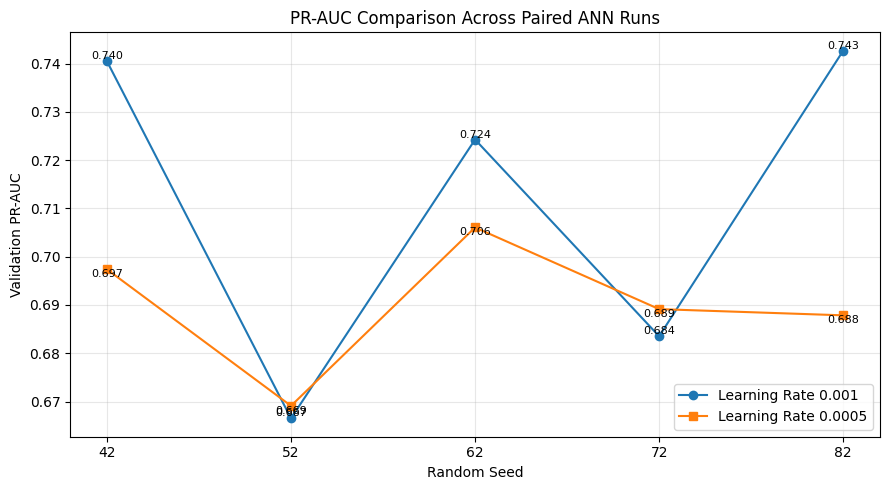

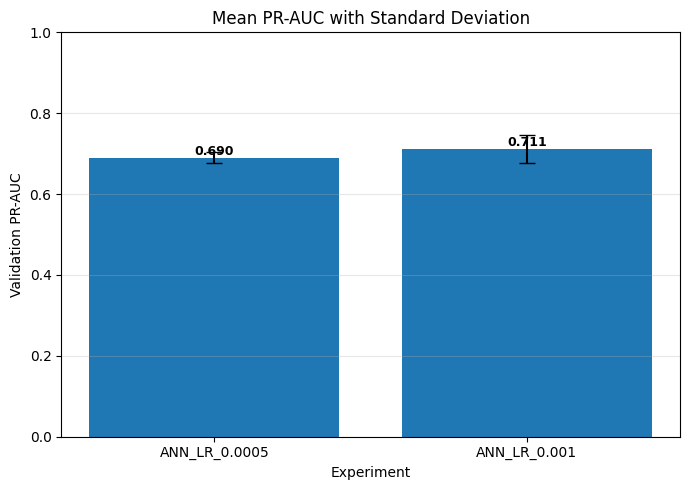

In [ ]:
# Visualize the experimental results

# ==========================
# 1. Paired PR-AUC Comparison
# ==========================

plt.figure(figsize=(9, 5))

plt.plot(
    paired_results.index,
    paired_results['ANN_LR_0.001'],
    marker='o',
    label='Learning Rate 0.001'
)

plt.plot(
    paired_results.index,
    paired_results['ANN_LR_0.0005'],
    marker='s',
    label='Learning Rate 0.0005'
)

# Add value labels
for x, y in zip(
        paired_results.index,
        paired_results['ANN_LR_0.001']):
    plt.text(x, y, f'{y:.3f}',
             ha='center', va='bottom', fontsize=8)

for x, y in zip(
        paired_results.index,
        paired_results['ANN_LR_0.0005']):
    plt.text(x, y, f'{y:.3f}',
             ha='center', va='top', fontsize=8)

plt.xlabel('Random Seed')
plt.ylabel('Validation PR-AUC')
plt.title('PR-AUC Comparison Across Paired ANN Runs')
plt.xticks(RANDOM_SEEDS)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ==========================
# 2. Mean PR-AUC with Standard Deviation
# ==========================

pr_auc_means = (
    experiment_results_df
    .groupby('Experiment')['PR_AUC']
    .mean()
)

pr_auc_stds = (
    experiment_results_df
    .groupby('Experiment')['PR_AUC']
    .std()
)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    pr_auc_means.index,
    pr_auc_means.values,
    yerr=pr_auc_stds.values,
    capsize=6
)

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{height:.3f}',
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

plt.ylabel('Validation PR-AUC')
plt.xlabel('Experiment')
plt.title('Mean PR-AUC with Standard Deviation')
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

#### Research Hypothesis Evaluation

The results do **not support the alternative hypothesis**.

The ANN with a learning rate of **0.001** achieved a higher average PR-AUC (**0.7115**) than the ANN with a learning rate of **0.0005** (**0.6899**).

The baseline configuration performed better in **3 of the 5 runs**, while the modified configuration performed better in **2 runs**.

Although the lower learning rate produced more consistent results (lower standard deviation), it achieved lower average PR-AUC, precision, and F1-score.

#### Conclusion

Reducing the learning rate from **0.001** to **0.0005** did not improve average validation PR-AUC. Based on the repeated runs, the original learning rate of **0.001** remains the preferred configuration.

The experiment also highlights the importance of evaluating ANN configurations using multiple runs rather than relying on a single training result, as model performance can vary across different random seeds.

In [104]:
# Save the experiment results to the required CSV file
experiment_results_df.to_csv(
    "experiment_results.csv",
    index=False
)

print("Experiment results saved successfully.")

Experiment results saved successfully.


## **Phase 5 — Business Interpretation**

In [105]:



# Generate failure-risk scores using the original Phase 2 ANN
y_val_risk_scores = ann_model.predict(
    X_val_scaled,
    verbose=0
).ravel()

# Assign risk categories
def assign_risk_band(score):
    if score < 0.30:
        return "Low"
    elif score < 0.70:
        return "Medium"
    else:
        return "High"

# Create validation risk classification
risk_analysis_df = pd.DataFrame({
    "Actual_Failure": np.asarray(y_val),
    "Risk_Score": y_val_risk_scores
})

risk_analysis_df["Risk_Category"] = (
    risk_analysis_df["Risk_Score"].apply(assign_risk_band)
)

# Summarize the number of records in each risk category
risk_summary = (
    risk_analysis_df["Risk_Category"]
    .value_counts()
    .reindex(["Low", "Medium", "High"], fill_value=0)
    .rename_axis("Risk_Category")
    .reset_index(name="Machine_Count")
)

risk_summary["Percentage"] = (
    risk_summary["Machine_Count"] / len(risk_analysis_df) * 100
)

print("Validation risk category distribution:")
display(risk_summary.round(2))

print("\nTotal validation records:", len(risk_analysis_df))
print("Actual failures:", int(risk_analysis_df["Actual_Failure"].sum()))


Validation risk category distribution:


,Risk_Category,Machine_Count,Percentage
0,Low,1378,91.87
1,Medium,42,2.80
2,High,80,5.33



Total validation records: 1500
Actual failures: 51


In [106]:

# Compare predicted risk categories with actual machine failures

risk_failure_summary = (
    risk_analysis_df
    .groupby("Risk_Category", observed=False)
    .agg(
        Total_Machines=("Actual_Failure", "count"),
        Actual_Failures=("Actual_Failure", "sum"),
        Mean_Risk_Score=("Risk_Score", "mean")
    )
    .reindex(["Low", "Medium", "High"])
    .fillna(0)
)

risk_failure_summary["Failure_Rate_Percentage"] = (
    risk_failure_summary["Actual_Failures"]
    / risk_failure_summary["Total_Machines"].replace(0, np.nan)
    * 100
)

display(risk_failure_summary.round(4))


,Total_Machines,Actual_Failures,Mean_Risk_Score,Failure_Rate_Percentage
Risk_Category,,,,
Low,1378,8,0.0131,0.5806
Medium,42,1,0.4837,2.3810
High,80,42,0.9280,52.5000


#### Machine Failure Risk Classification

The selected ANN model was used to generate risk scores for the **1,500 validation records**. Three risk categories were defined:

| Risk Category | Score Range |
|--------------|-------------|
| Low Risk | < 0.30 |
| Medium Risk | 0.30 to < 0.70 |
| High Risk | ≥ 0.70 |

#### Risk Category Results

| Risk Category | Machines | Actual Failures | Failure Rate |
|---------------|---------:|---------------:|-------------:|
| Low | 1,378 | 8 | 0.58% |
| Medium | 42 | 1 | 2.38% |
| High | 80 | 42 | 52.50% |

#### Key Findings

- The **high-risk group** contained **42 of the 51 actual failures**.
- This corresponds to a **failure capture rate of 82.35%**.
- Only **5.33%** of validation machines were classified as high risk, making this group suitable for prioritized inspection.
- However, **9 failures** occurred in the low- and medium-risk groups, so a low-risk classification should not be treated as a guarantee of no failure.

#### Conclusion

The ANN risk categories help identify machines that may require closer monitoring. The high-risk group captured most failures while representing a small proportion of machines, supporting its use as a decision-support tool for maintenance planning.

#### Important Sensor Patterns and Business Interpretation

The exploratory analysis identified several sensor patterns associated with machine failures:

- **Higher Torque and Tool Wear:** Failed machines generally showed higher torque and tool wear values.
- **Lower Rotational Speed:** Failed machines tended to operate at lower rotational speeds.
- **Temperature Relationship:** Air temperature and process temperature showed a strong positive correlation (**0.88**), meaning they tend to increase together.
- **Speed and Torque Relationship:** Rotational speed and torque showed a strong negative correlation (**-0.88**), meaning higher speed is often associated with lower torque.
- **High-Speed, Low-Torque Pattern:** A small group of 24 machines with high speed and low torque contained 22 failures, suggesting a pattern worth further investigation.

#### Business Interpretation

Torque, tool wear, and rotational speed appear to be useful indicators for monitoring machine condition and identifying higher-risk machines.

The strong correlations between some sensor measurements also suggest that certain variables contain similar information.

These patterns should be viewed as indicators rather than direct causes of machine failure. Additional testing with real operational data is required before using them as maintenance rules.

### **Recommended Maintenance Actions and Deployment Constraints**

#### Recommended Maintenance Actions

Based on the risk categories defined using the ANN model:

| Risk Category | Risk Score | Recommended Maintenance Action |
|---|---|---|
| **Low** | Below 0.30 | Continue routine maintenance and normal sensor monitoring. Reassess the machine when new sensor readings become available. |
| **Medium** | 0.30 to below 0.70 | Add the machine to a watchlist. Increase monitoring frequency and schedule a targeted inspection when operationally appropriate. |
| **High** | 0.70 or above | Give the machine priority for inspection. Ask maintenance personnel to examine relevant operating conditions, including torque, tool wear, and rotational speed, before deciding on corrective action. |

The high-risk category captured 42 out of 51 actual failures in the validation dataset. This indicates that the proposed threshold can help prioritize machines for inspection. However, 38 machines classified as high risk did not experience a recorded failure in the validation data, so inspections will also involve some unnecessary inspection effort.

#### Constraints Before Real-World Deployment

The model should be treated as a decision-support tool rather than an automatic machine-control system. Several limitations must be addressed before deployment:

1. **Synthetic Dataset:** The model was developed using the AI4I 2020 synthetic dataset. Its performance may not directly represent real industrial machines and operating environments.

2. **Limited Failure Records:** Only 339 out of 10,000 records represent machine failures. The limited number of failure examples may affect the model's ability to generalize to different failure conditions.

3. **Hypothetical Inspection Costs:** The inspection and missed-failure costs used during threshold selection were assumed for experimentation. Actual maintenance costs, downtime costs, and failure consequences must be obtained from the organization.

4. **Model Reliability:** The model must be tested using real-world data from different machines, operating conditions, and time periods. Its performance should be monitored regularly to identify changes in prediction quality.

5. **Sensor Reliability:** Incorrect, missing, or noisy sensor readings may affect predictions. Sensor calibration, data-quality checks, and monitoring are necessary.

6. **Human Verification:** High-risk predictions should trigger inspection and review by qualified maintenance personnel. The model should not independently shut down machines or initiate repairs.

7. **Threshold Reassessment:** The selected risk thresholds should be reviewed when actual failure rates, inspection capacity, and maintenance costs become available.

#### Final Recommendation

The ANN model is recommended as a preliminary machine-failure risk prioritization tool, using a threshold of 0.70 for the high-risk category. This recommendation considers its validation performance and the explicitly hypothetical inspection and missed-failure costs evaluated earlier.

Before operational use, the model requires validation on real industrial data, cost verification, sensor-quality checks, and continuous performance monitoring. Maintenance decisions should remain under human supervision.

In [108]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Generate failure-risk scores using the original Phase 2 ANN
y_test_risk_scores = ann_model.predict(
    X_test_scaled, verbose=0
).ravel()

# Apply the previously selected threshold
selected_threshold = 0.70

y_test_pred = (
    y_test_risk_scores >= selected_threshold
).astype(int)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, zero_division=0)
test_recall = recall_score(y_test, y_test_pred, zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, zero_division=0)
test_roc_auc = roc_auc_score(y_test, y_test_risk_scores)
test_pr_auc = average_precision_score(y_test, y_test_risk_scores)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test, y_test_pred, labels=[0, 1]
).ravel()

# Hypothetical costs used earlier
inspection_cost = 2000
missed_failure_cost = 25000

test_estimated_cost = (
    fp * inspection_cost +
    fn * missed_failure_cost
)

print("ANN - Final Test Results")
print("------------------------")
print(f"Threshold: {selected_threshold}")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall: {test_recall:.4f}")
print(f"F1-score: {test_f1:.4f}")
print(f"ROC-AUC: {test_roc_auc:.4f}")
print(f"PR-AUC: {test_pr_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred, labels=[0, 1]))

print("\nPrediction Counts:")
print(f"True Negatives: {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives: {tp}")

print("\nEstimated Test-set Cost")
print("-----------------------")
print(f"Inspection Cost: ₹{fp * inspection_cost:,.0f}")
print(f"Missed Failure Cost: ₹{fn * missed_failure_cost:,.0f}")
print(f"Total Estimated Cost: ₹{test_estimated_cost:,.0f}")

ANN - Final Test Results
------------------------
Threshold: 0.7
Accuracy: 0.9573
Precision: 0.4301
Recall: 0.7843
F1-score: 0.5556
ROC-AUC: 0.9768
PR-AUC: 0.7186

Confusion Matrix:
[[1396   53]
 [  11   40]]

Prediction Counts:
True Negatives: 1396
False Positives: 53
False Negatives: 11
True Positives: 40

Estimated Test-set Cost
-----------------------
Inspection Cost: ₹106,000
Missed Failure Cost: ₹275,000
Total Estimated Cost: ₹381,000


#### **Final Evaluation on the Test Dataset**

The selected ANN model was evaluated on the unseen test dataset using the chosen threshold of **0.70**.

#### **Test Performance**

| Metric | Value |
|----------|----------:|
| Accuracy | 95.73% |
| Precision | 43.01% |
| Recall | 78.43% |
| F1-Score | 55.56% |
| ROC-AUC | 97.68% |
| PR-AUC | 71.86% |

#### **Confusion Matrix Summary**

| Measure | Count |
|----------|------:|
| True Positives | 40 |
| False Negatives | 11 |
| False Positives | 53 |
| True Negatives | 1,396 |

#### **Key Findings**

- The model correctly identified **40 of 51 machine failures**.
- The estimated business cost was **₹3,81,000** under the hypothetical cost assumptions.
- Compared with validation results, recall and PR-AUC were slightly lower on the test dataset.
- Despite this decrease, the model maintained strong overall ranking performance.

#### **Conclusion**

The ANN demonstrated good performance on unseen data and retained its ability to prioritize higher-risk machines. These results support its use as a predictive maintenance decision-support tool. However, further validation using real operational data and actual maintenance costs is recommended before deployment.